# Use Kasumi (MISTy with sliding windows) on MIBI data

## Imports

In [1]:
library(mistyR)
library(kasumi)
library(tidyverse)
library(future)
library(proxy)
library(withr)
library(igraph)
source("../.utils/plot_style.R")

mistyR is able to run computationally intensive functions
  in parallel. Please consider specifying a future::plan(). For example by running
  future::plan(future::multisession) before calling mistyR functions.

Kasumi is able to run computationally intensive functions
  in parallel. Please consider specifying a future::plan(). For example by running
  future::plan(future::multisession) before calling Kasumi functions.

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘proxy’


The following objects 

## Helper functions

In [2]:
leiden_onsim <- function(representation, minsim = 0.8, resolution = 0.8, measure = "cosine") {
  sim <- simil(representation, measure)

  sim[sim < minsim] <- 0
  with_seed(
    1,
    groups <-
      graph.adjacency(sim %>% as.matrix(), mode = "undirected", weighted = TRUE) %>%
      cluster_leiden(resolution_parameter = resolution, n_iterations = -1)
  )

  return(groups$membership)
}

In [3]:
sm_repr <- function(misty.results, cuts, res, cutoff = 0, trim = 1) {
  # trimming matters
  sig <- extract_signature(misty.results, type = "i", intersect.targets = FALSE, trim = trim)
  sig[is.na(sig)] <- floor(min(sig %>% select(-sample), na.rm = TRUE))
  sig <- sig %>% mutate(across(!sample, ~ ifelse(.x <= cutoff, 0, .x)))

  keep <- which(sig %>% select(-sample, -contains("intra_")) %>% rowSums() != 0)

  samps <- sig %>%
    dplyr::slice(keep) %>%
    select(sample) %>%
    mutate(
      id = str_extract(sample, ".*/") %>% str_remove("/"), # Sample names should not contain "/"
      box = str_extract(sample, "/[0-9].*$") %>% str_remove("/")
    ) %>%
    rowwise(id) %>%
    summarize(rebox = box %>%
      str_split("_", simplify = T) %>%
      as.numeric() %>% list(), .groups = "drop") %>%
    rowwise(id) %>%
    summarize(
      xcenter = (rebox[3] + rebox[1]) / 2,
      ycenter = (rebox[4] + rebox[2]) / 2, .groups = "drop"
    )

  # the filtering here also matters
  clean <- sig %>%
    select(-sample, -contains("_.novar")) %>%
    dplyr::slice(keep) %>%
    select(where(~ sum(.) != 0))


  clusters <- leiden_onsim(clean, cuts, res)

  suppressMessages(
    sm.repr <- map(clusters, ~ .x == seq(length(unique(clusters)))) %>% reduce(rbind) %>%
      as_tibble(.name_repair = "unique") %>% cbind(samps) %>% group_by(id) %>%
      rename(x = xcenter, y = ycenter) %>%
      group_split()
  )


  return(sm.repr)
}

In [4]:
sm_labels <- function(misty.results, cuts, res, cutoff = 0, trim = 1, freq = TRUE) {
  sm.repr <- sm_repr(misty.results, cuts, res, cutoff, trim)

  if (!freq) {
    return(sm.repr)
  }

  repr.ids <- sm.repr %>% map_chr(~ .x$id[1])

  # technically we can also use pa_repr instead of freq_repr or combine both
  freq.sm <- sm.repr %>%
    map_dfr(~ .x %>%
      select(-c(id, x, y)) %>%
      freq_repr()) %>%
    select(where(~ (sd(.) > 1e-3) & (sum(. > 0) >= min(length(repr.ids), max(5, 0.1 * length(.)))))) %>%
    add_column(id = repr.ids, .before = 1)

  return(freq.sm)
}

In [5]:
freq_repr <- function(labels) {
  colSums(labels) / sum(labels)
}

## Load

In [6]:
# Load your transformed cell table
cells = read_csv("../../data/cell_table_with_types_stage.csv")
head(cells)

New names:
• `` -> `...1`
Rows: 579011 Columns: 70
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (31): fov, annotation_t, annotation_scyan, consensus, annotation_consens...
dbl (37): ...1, CA9, nuclei, CD98, CytC, MSH2, MCT1, PDL1, PD1, ASCT2, LDH, ...
lgl  (2): Grade raw, pM group

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


...1,CA9,nuclei,CD98,CytC,MSH2,MCT1,PDL1,PD1,ASCT2,⋯,RAS Mutation RED,RAS Mutation RED 2,BRAF Mutation RED,HER2 Amplifikation,Age,Sex,MIBI,Tumor Size Group,Age Group,Stage
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<dbl>,<chr>,<chr>
0,0.02128943,0.04614832,0.006392956,0.01571343,0.02473370,0.0001934555,0.009022579,0.004549611,0.04586374,⋯,NA,NA,NA,NA,88,w,acquired,NA,70 and Over,pT3
1,0.01457781,0.03423819,0.008830998,0.10651270,0.06347377,0.0027742222,0.004172783,0.000000000,0.02873399,⋯,NA,NA,NA,NA,88,w,acquired,NA,70 and Over,pT3
2,0.11329879,0.06419776,0.034138213,0.01142891,0.06656348,0.0015064266,0.009497505,0.000000000,0.02825994,⋯,NA,NA,NA,NA,88,w,acquired,NA,70 and Over,pT3
3,0.12827739,0.09715288,0.040913454,0.03036816,0.01601639,0.0052802216,0.022267382,0.028413114,0.03409141,⋯,NA,NA,NA,NA,88,w,acquired,NA,70 and Over,pT3
4,0.10768224,0.05414692,0.070130227,0.09855133,0.08103716,0.0209243360,0.004453675,0.022994452,0.11757625,⋯,NA,NA,NA,NA,88,w,acquired,NA,70 and Over,pT3
5,0.10965646,0.01982199,0.026331486,0.06694059,0.02464267,0.0497367896,0.001608107,0.027431549,0.19049839,⋯,NA,NA,NA,NA,88,w,acquired,NA,70 and Over,pT3


In [7]:
# Exclude low epithelial abundance samples and SCT samples (start with "E1" or "E2")

# See StageXGB.ipynb
excluded_fovs = c('A2n','A3r','A4i','A5c','A7c','A7m','A8f','A9k','A9p','B1q','B2l',
                  'B2n','B3o','B4a','B4n','B5h','B5i','B5p','B6l','B7g','B7k','B7q',
                  'B8c','B9r','C2e','C9a','C9d','C9e','C9i','D1c','D1g','D2c','D3m',
                  'D4e','D6e','D6i','D7b','D8m','D9g','D9l')

cells <- cells %>% 
    filter(!(fov %in% excluded_fovs)) %>%
    filter(!grepl("^E[1-2]", fov))

## Format for Kasumi

In [8]:
ws <- 256 # Window size, similar to other MIBI datasets, split FOV in 4x4
paraview_l <- 120 # Distance in pixels up to which an effect will be considered in the paraview
juxtaview_l <- 40 # Distance in pixels up to which a cell is considered a direct neighbor
panel = c('CA9', 'CD98', 'CytC', 'MCT1', 'ASCT2', 'LDH', 'GS', 'GLS', 'ATP5A', 'CS', 'PKM2', 'GLUT1', 'ARG1', 'CPT1A', 'Ki67')  # Markers to be used for the analysis
outputfile = "kasumi_colorectal_metab_256.sqm"

In [9]:
# Expected data is a list of tibbles with each one containing the marker expressions (columns) per cell (rows) for a fov
markers <- cells %>% group_by(fov) %>% select(all_of(panel)) %>% group_split(.keep = FALSE)

Adding missing grouping variables: `fov`


In [10]:
# Coordinates of each cell
positions <- cells %>% group_by(fov) %>% 
    mutate(x = `centroid-0`, y = `centroid-1`) %>%
    select(fov, x, y) %>%
    group_split(.keep = FALSE)

## Run Kasumi

In [11]:
# Keep track of the order of the FOVs in the markers table / kasumi output
deduplicated_cells <- cells %>%
  group_by(fov) %>%
  dplyr::slice(1) %>%
  ungroup()

In [ ]:
# Apply the function to each marker
outputs <- seq_along(markers) %>% walk(
# outputs <- seq(from = 201, to = length(markers)) %>% walk(
    function(i) {
    print(i)
    misty.views <- create_initial_view(markers[[i]]) %>%
        add_paraview(positions[[i]], paraview_l,
            family = "gaussian", cached = TRUE,
            prefix = "p.", zoi = juxtaview_l,
        ) %>%
        add_juxtaview(positions[[i]], juxtaview_l,
            prefix = "l."
        )

    folders <- run_kasumi(misty.views, positions[[i]], ws,
        sample.id = deduplicated_cells$fov[i],
        results.db = outputfile,
        bypass.intra = FALSE,
        cv.strict = TRUE,
        minu = 20,
        overlap = 0,
        sqlite_timeout = 100
    )})

# # Copy the output file to roll back to later it if necessary
# file.copy(outputfile, paste0(outputfile, ".200.bak"))

[1] 1



Computing triangulation


Generating juxtaview


Sliding

Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target CA9”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target CytC”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target MCT1”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target ASCT2”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target LDH”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target PKM2”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target GLUT1”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target ARG1”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target Ki

[1] 2



Computing triangulation


Generating juxtaview


Sliding

Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target MCT1”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target LDH”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target GS”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target GLS”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target CS”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target GLUT1”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target Ki67”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target CA9”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target CD98”
Wa

[1] 3



Computing triangulation


Generating juxtaview


Sliding

Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target CA9”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target CD98”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target CytC”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target MCT1”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target ASCT2”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target LDH”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target GS”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target GLS”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target ATP5A”

... (712 outputs left out)

[1] 360



Computing triangulation


Generating juxtaview


Sliding

Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target CytC”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target GS”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target PKM2”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target GLUT1”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target ARG1”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target Ki67”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target CD98”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target GS”
Warning message in ...furrr_fn(...):
“Negative performance detected and replaced with 0 for target GLUT1

[1] 361



Computing triangulation


Generating juxtaview


Sliding



If the process is interrupted, you can resume from the last checkpoint after cleanup:
```Python
# Remove corrupted output file and replace it with back up
file.remove(outputfile)
file.copy(paste0(outputfile, ".100.bak"), outputfile)
```

In [12]:
plan(multisession, workers = 30) # Bring up when no other users are active

In [12]:
misty.results <- collect_results(outputfile)

In [ ]:
write_rds(misty.results, paste0(str_remove(outputfile, ".sqm"), ".rds"), "gz")

In [13]:
misty.results <- read_rds(paste0(str_remove(outputfile, ".sqm"), ".rds"))

In [14]:
# Get unique FOVs (first part of samples)
fov.results <- misty.results$contributions$sample %>% 
    strsplit("/") %>%
    map_chr(~ .x[1]) %>%
    unique()
# Are all samples present?

print(fov.results %>% length())
print(fov.results)

[1] 423
  [1] "A1a" "A1c" "A1d" "A1e" "A1f" "A1h" "A1i" "A1k" "A1l" "A1m" "A1n" "A1o"
 [13] "A1p" "A1q" "A1r" "A2a" "A2b" "A2c" "A2d" "A2e" "A2g" "A2h" "A2i" "A2k"
 [25] "A2l" "A2m" "A2o" "A2p" "A2q" "A2r" "A3a" "A3b" "A3c" "A3d" "A3e" "A3f"
 [37] "A3g" "A3h" "A3i" "A3l" "A3m" "A3n" "A3o" "A3p" "A3q" "A4a" "A4b" "A4c"
 [49] "A4d" "A4e" "A4f" "A4h" "A4k" "A4l" "A4m" "A4n" "A4o" "A4p" "A4q" "A4r"
 [61] "A5a" "A5b" "A5d" "A5e" "A5f" "A5g" "A5i" "A5k" "A5l" "A5m" "A5n" "A5o"
 [73] "A5p" "A5q" "A6b" "A6c" "A6d" "A6e" "A6g" "A6h" "A6i" "A6k" "A6l" "A6m"
 [85] "A6n" "A6o" "A6p" "A6q" "A6r" "A7a" "A7b" "A7d" "A7f" "A7g" "A7h" "A7k"
 [97] "A7l" "A7n" "A7o" "A7p" "A7q" "A7r" "A8a" "A8b" "A8c" "A8d" "A8e" "A8g"
[109] "A8h" "A8i" "A8l" "A8m" "A8n" "A8o" "A8p" "A8q" "A8r" "A9a" "A9b" "A9c"
[121] "A9d" "A9e" "A9f" "A9g" "A9h" "A9i" "A9l" "A9m" "A9n" "A9o" "A9q" "A9r"
[133] "B1a" "B1b" "B1c" "B1d" "B1e" "B1f" "B1g" "B1h" "B1i" "B1k" "B1n" "B1o"
[145] "B1p" "B2a" "B2b" "B2c" "B2e" "B2f" "B2g" "B2h" "B

## Visualize model performance across samples

In [15]:
c <- misty.results$contributions
c %>% head()
c[c$value %>% is.na(), "target"] %>% table

target,sample,view,value
<chr>,<chr>,<chr>,<dbl>
CA9,A1a/3.4_4.33_259.4_260.33,intercept,-0.02702815
CA9,A1a/3.4_4.33_259.4_260.33,intraview,1.11247264
CA9,A1a/3.4_4.33_259.4_260.33,paraview.120,0.33880481
CA9,A1a/3.4_4.33_259.4_260.33,juxtaview.40,-0.01364529
CA9,A1a/3.4_4.33_259.4_260.33,p.intercept,NA
CA9,A1a/3.4_4.33_259.4_260.33,p.intraview,0.00000000


target
 ARG1 ASCT2 ATP5A   CA9  CD98 CPT1A    CS  CytC   GLS GLUT1    GS  Ki67   LDH 
 6459  6459  6458  6459  6458  6459  6459  6459  6459  6459  6459  6459  6458 
 MCT1  PKM2 
 6453  6459 

In [16]:
# Define custom and concistent parameters
c_trim = 1
c_cutoff = 0.9

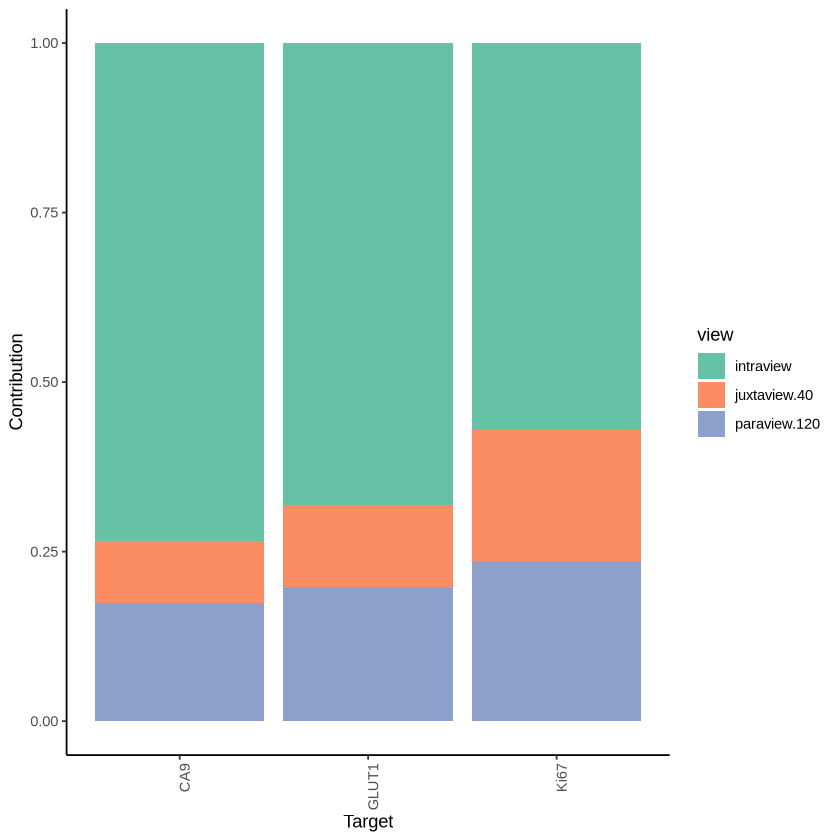

In [17]:
plot_view_contributions(misty.results, trim = c_trim)

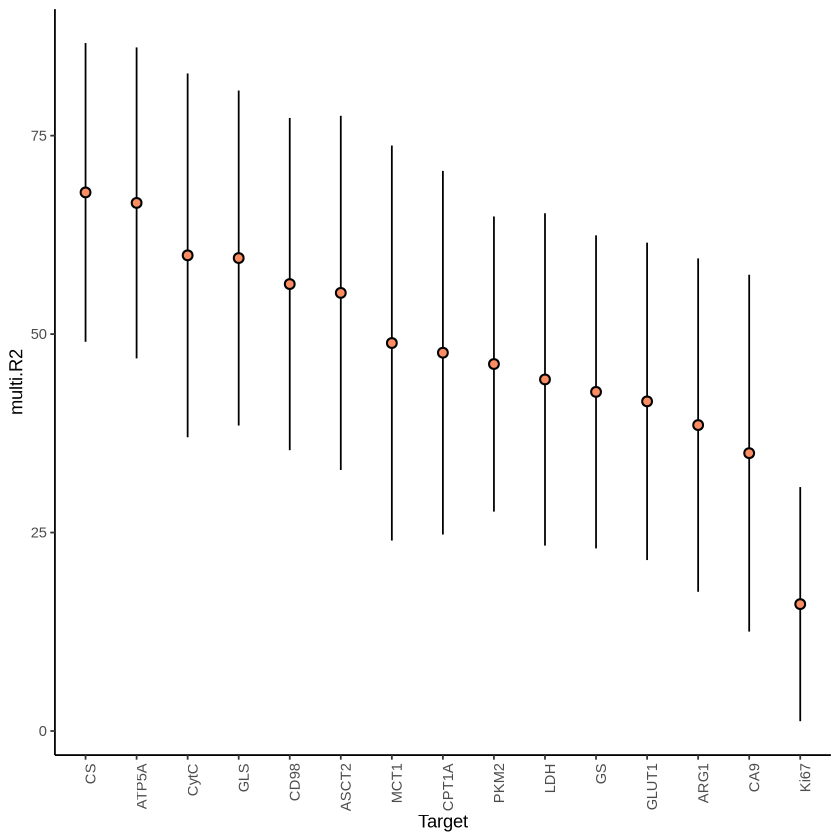

In [18]:
# Combined performance
plot_improvement_stats(misty.results, measure = "multi.R2", trim = c_trim)

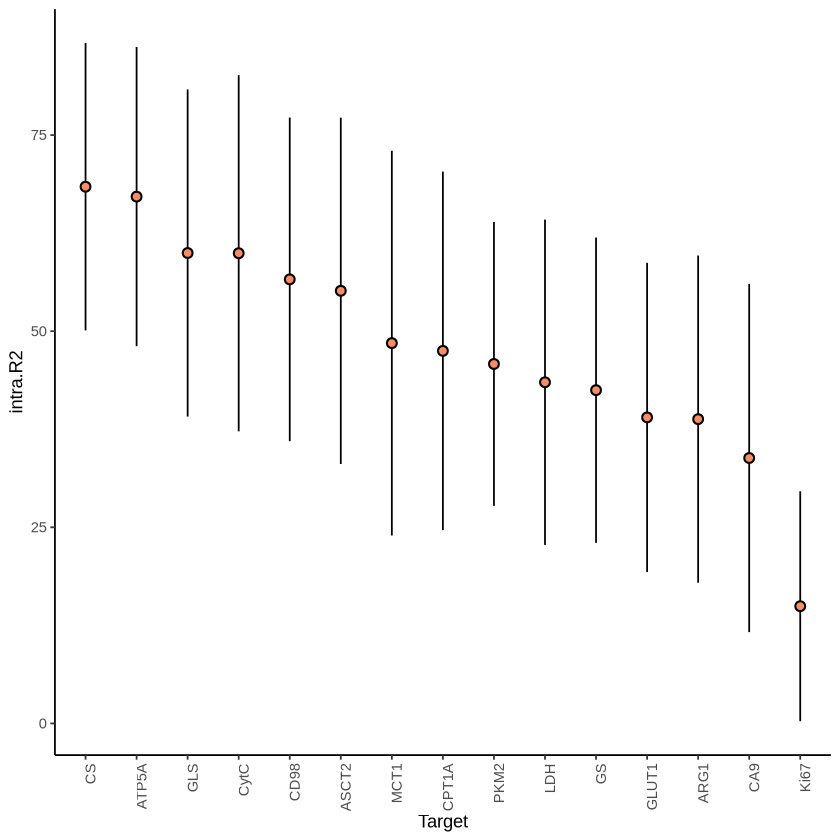

In [19]:
# Performance for intra only, show all markers
layout_scale <- 0.51  # Fig 4h is placed at 51% of its saved size
plot_improvement_stats(misty.results, measure = "intra.R2", trim = 0)
ggsave(filename = "../../figures/fig4/misty_metab_intra.pdf",
       plot = last_plot() + paper_theme(layout_scale), width = 4, height = 4)

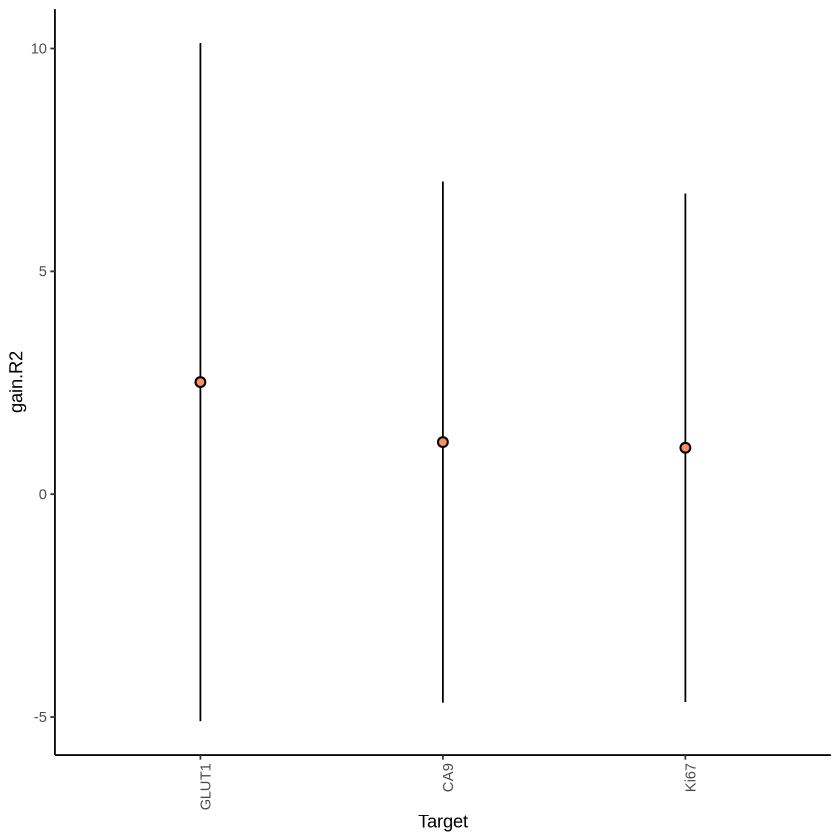

In [20]:
# Spatial gain in performance
# plot_improvement_stats(misty.results, trim = 0) # Any positive gain
layout_scale <- 0.50  # Fig 4i is placed at 50% of its saved size
plot_improvement_stats(misty.results, trim = c_trim) # Positive gain above threshold
ggsave(filename = "../../figures/fig4/misty_metab_improvements.pdf",
       plot = last_plot() + paper_theme(layout_scale), width = 2, height = 4)

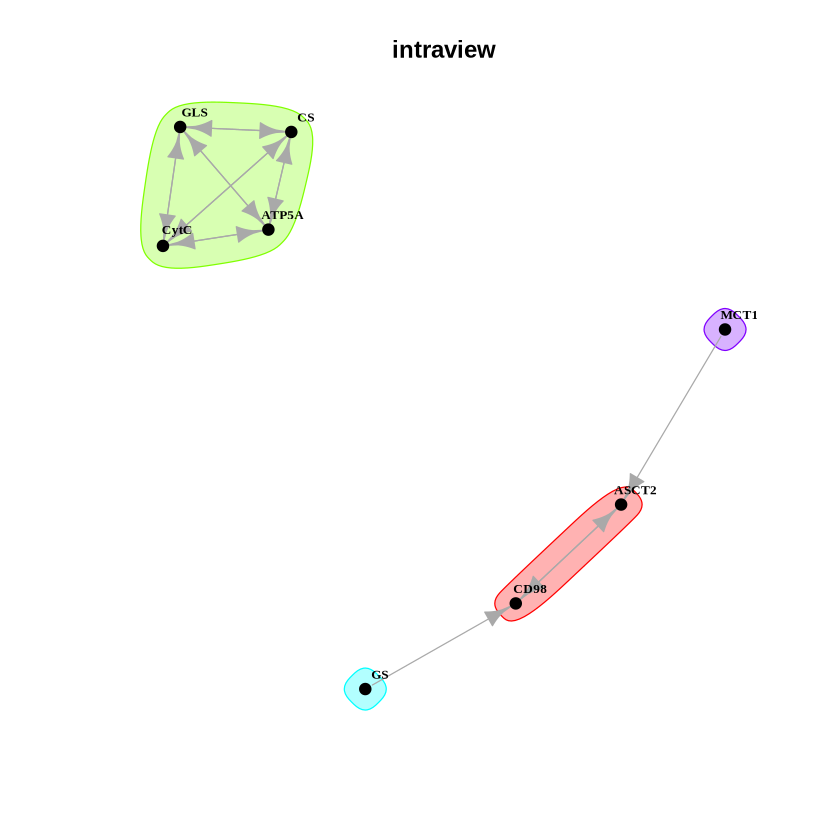

In [21]:
# plot_interaction_communities(misty.results, view = "intraview", trim = 50, cutoff = c_cutoff, trim.measure = "intra.R2")
plot_interaction_communities(misty.results, view = "intraview", 
    trim = 50, cutoff = c_cutoff, 
    trim.measure = "intra.R2",
    path = "../../data/kasumi_metab_intra_net.graphml")
# plot_interaction_heatmap(misty.results, view = "intraview", clean = TRUE, correlation = TRUE, 
#                          trim = c_trim, cutoff = c_cutoff, trim.measure = "intra.R2")

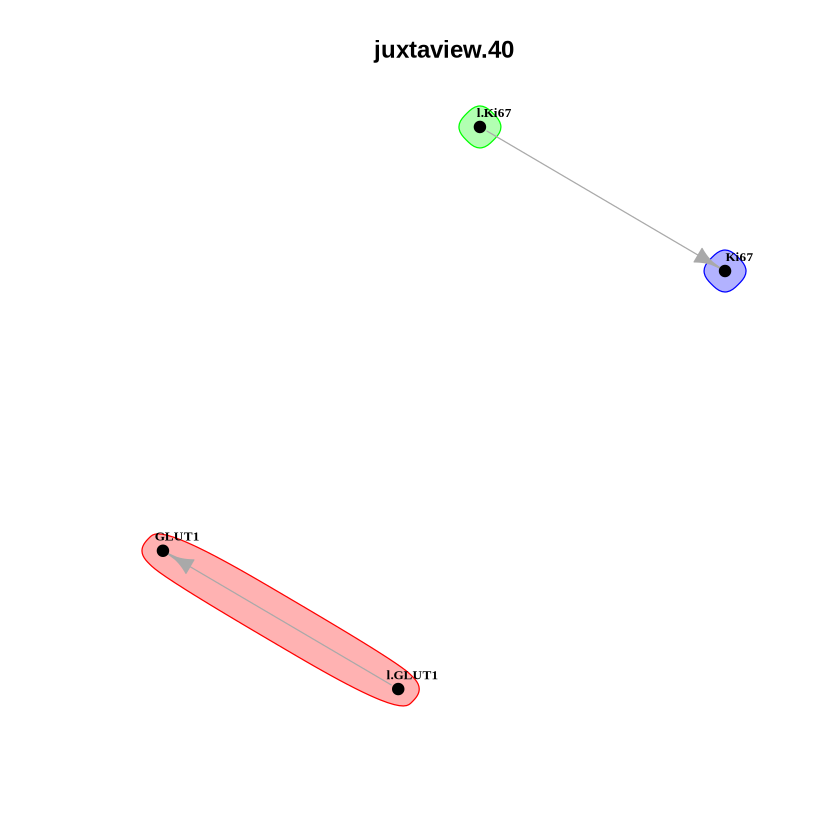

In [22]:
plot_interaction_communities(misty.results, view = "juxtaview.40", trim = c_trim, cutoff = c_cutoff)

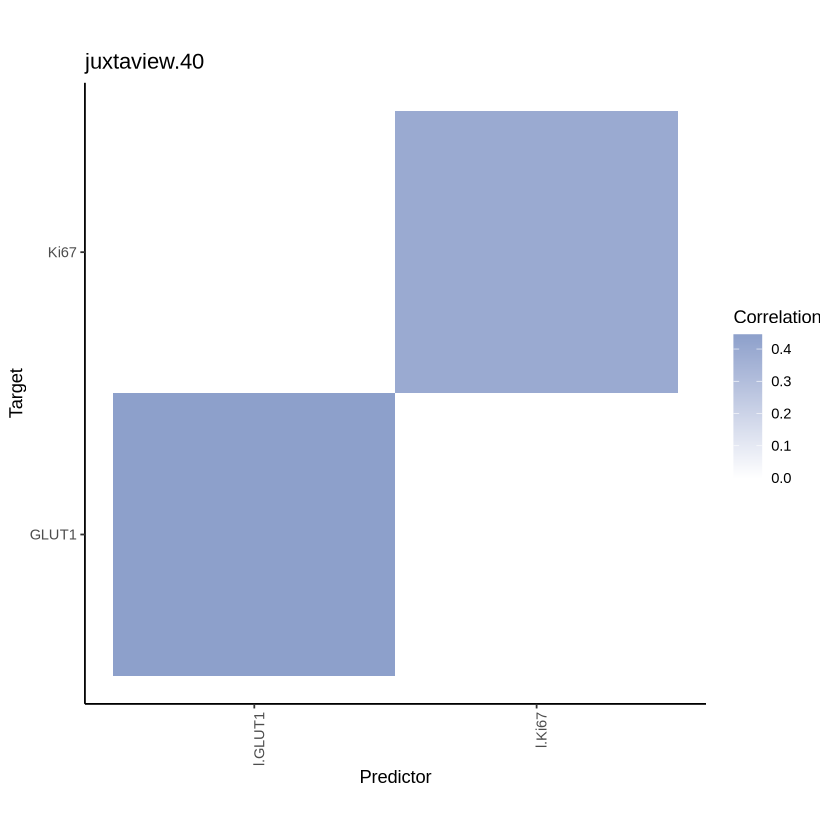

In [23]:
plot_interaction_heatmap(misty.results, view = "juxtaview.40", clean = TRUE, correlation = TRUE, trim = c_trim, cutoff = c_cutoff)
ggsave(filename = "../../figures/fig4/misty_metab_juxtaview_heatmap.pdf", 
       width = 4, height = 3, dpi = 300)

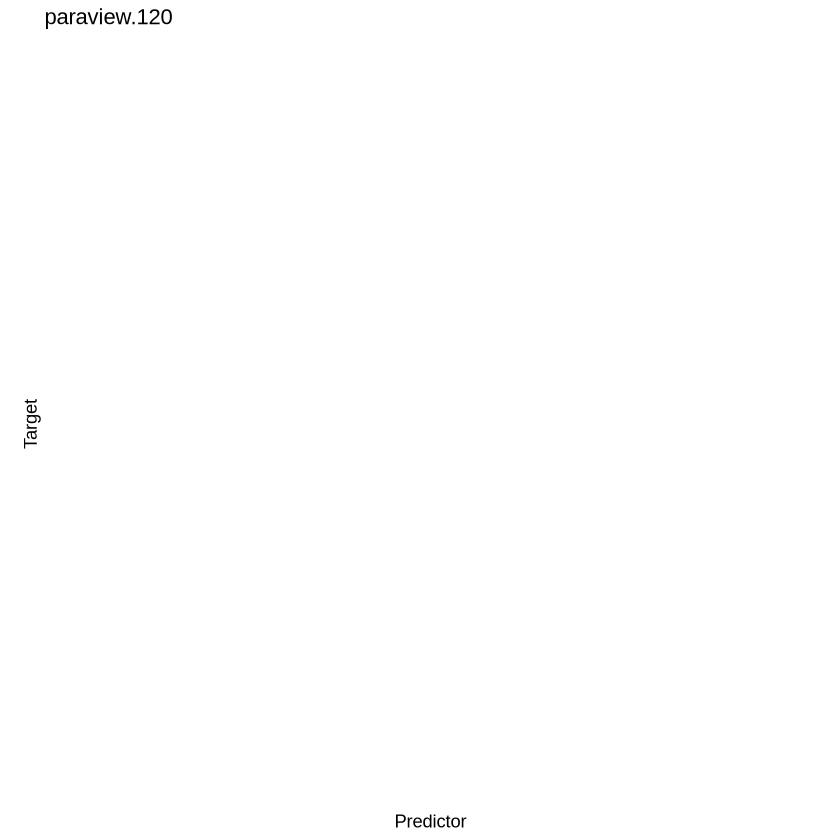

In [24]:
plot_interaction_heatmap(misty.results, view = "paraview.120", clean = TRUE, correlation = TRUE, trim = c_trim, cutoff = c_cutoff)

## Get and export window clusters

Export overall association significances

In [25]:
fov_features <- extract_signature(misty.results, type = "i", intersect.targets = FALSE, trim = c_trim)
print(dim(fov_features))
fov_features[is.na(fov_features)] <- floor(min(fov_features %>% select(-sample), na.rm = TRUE))
fov_features <- fov_features %>% mutate(across(!sample, ~ ifelse(.x <= c_cutoff, 0, .x)))
# Drop columns with all zeros
keep <- names(which(fov_features %>% select(-sample, -contains("intraview_")) %>% colSums() > 0))
fov_features <- fov_features %>%
    select(sample, all_of(keep)) %>%
    mutate(
        fov = str_extract(sample, ".*/") %>% str_remove("/")
    ) %>% 
    group_by(fov) %>%
    summarize(across(!sample, ~ median(.x, na.rm = TRUE)), .groups = "drop")
keep <- names(which(fov_features %>% select(-fov) %>% colSums() > 0))
fov_features %>%
    select(fov, all_of(keep)) %>%
    write_csv("../../data/kasumi_metab_features.csv")

[1] 6459  136


We take the clusters that led to the best modelling of disease stages, if any (see *StageXGB.ipynb*).

In [26]:
# Coefficients for the clustering
c_cuts = 0.35
c_res = 0.4

In [27]:
sm.repr <- sm_labels(misty.results, cuts = c_cuts, res = c_res, cutoff = c_cutoff, trim = c_trim)
sm.repr.ext <- sm_labels(misty.results, cuts = c_cuts, res = c_res, cutoff = c_cutoff, trim = c_trim, freq=FALSE)

## Visualize clusters in each FOV

In [28]:
library(extraDistr)
library(ggrepel)
library(RColorBrewer)


Attaching package: ‘extraDistr’


The following object is masked from ‘package:purrr’:

    rdunif




In [29]:
freq_all_clusters <- sapply(sm.repr.ext, 
      function(x) x %>%
           select(-id, -x, -y) %>%
           colSums)

# Compile cluster stats

cluster_stats <- data.frame(samples = rowSums(freq_all_clusters > 0))

cluster_stats$names <- sm.repr.ext[[1]] %>%
           select(-id, -x, -y) %>%
           names

cluster_stats$windows <- rowSums(freq_all_clusters)
cluster_stats$selected <- cluster_stats$names %in% names(sm.repr)

# Number of samples, pop size per class, number of draws
expected_samples_for_x_windows <- function(x, repet = 1000){
    X = rmvhyper(repet, sapply(sm.repr.ext, nrow), x)
    X = rowSums(X > 0)
    return(quantile(x = X, probs = c(0.1,0.5,0.9)))
}

with_seed(
  42,
    expected_samples_per_windows <- sapply(min(cluster_stats$windows):max(cluster_stats$windows), 
            expected_samples_for_x_windows)
)

expected_samples_per_windows = data.frame(t(expected_samples_per_windows))
expected_samples_per_windows$windows = min(cluster_stats$windows):max(cluster_stats$windows)
expected_samples_per_windows$selected = "Expectation"

In [30]:
cluster_stats$names <- str_remove(string = cluster_stats$names, pattern = "...")
# Label clusters if they have an unusual number of samples compared to their number of windows
lowsamples <- (cluster_stats %>% 
    left_join(expected_samples_per_windows, by = "windows") %>%
    mutate(lowsamples = X10. > samples))$lowsamples
cluster_stats$label <- ifelse(lowsamples, cluster_stats$names, NA)
# Label clusters if selected
cluster_stats$label_selected <- ifelse(cluster_stats$selected, cluster_stats$names, NA)

Warning message:
“Removed 463 rows containing missing values or values outside the scale range
(`geom_text_repel()`).”
Warning message:
“ggrepel: 9 unlabeled data points (too many overlaps). Consider increasing max.overlaps”
Warning message:
“Removed 463 rows containing missing values or values outside the scale range
(`geom_text_repel()`).”
Warning message:
“ggrepel: 7 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


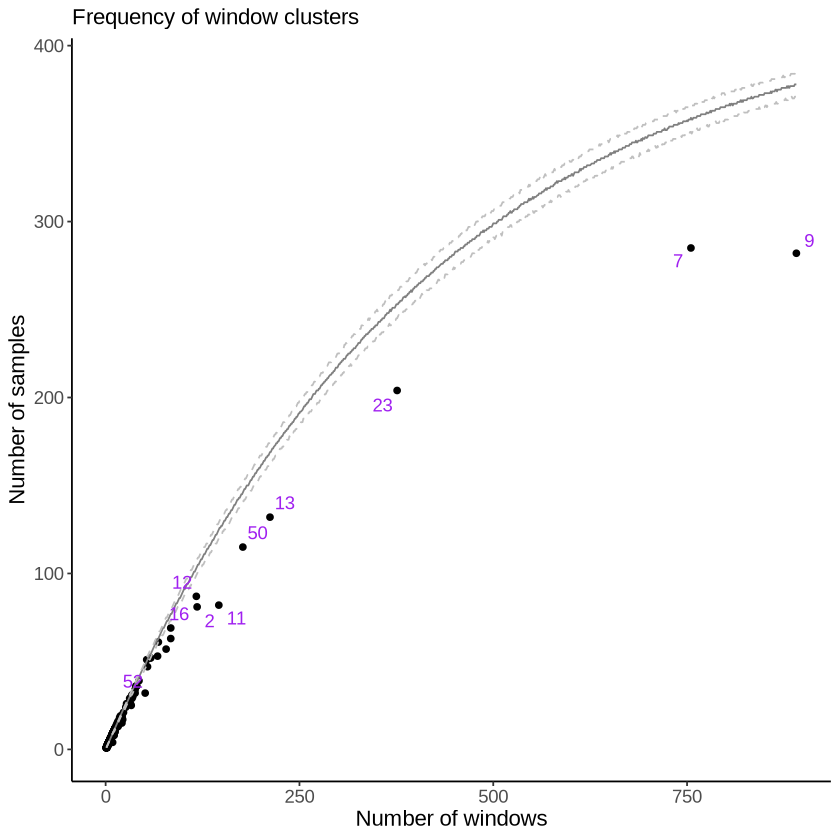

In [31]:
# Plot and save
layout_scale <- 0.45  # Fig S7i is placed at 45% of its saved size
gp <- ggplot(cluster_stats, aes(y = samples, x = windows)) +
    geom_point() +
    theme_classic() + 
    geom_line(data = expected_samples_per_windows,
               aes(y = X50., x = windows), color = "gray50") + 
     geom_line(data = expected_samples_per_windows,
               aes(y = X90., x = windows), color = "gray75", lty = 2) + 
     geom_line(data = expected_samples_per_windows,
               aes(y = X10., x = windows), color = "gray75", lty = 2) +
    #  geom_text_repel(aes(label = label), color = "gray75") +
     geom_text_repel(aes(label = label_selected), color = "purple", size = paper_text_size(layout_scale)) +
     ggtitle("Frequency of window clusters") +
     xlab("Number of windows") + 
     ylab("Number of samples") +
     paper_theme(layout_scale)
ggsave("../../figures/fig4/kasumi_cluster_frequency.pdf", plot = gp,
       width = 4, height = 4, dpi = 300)
gp

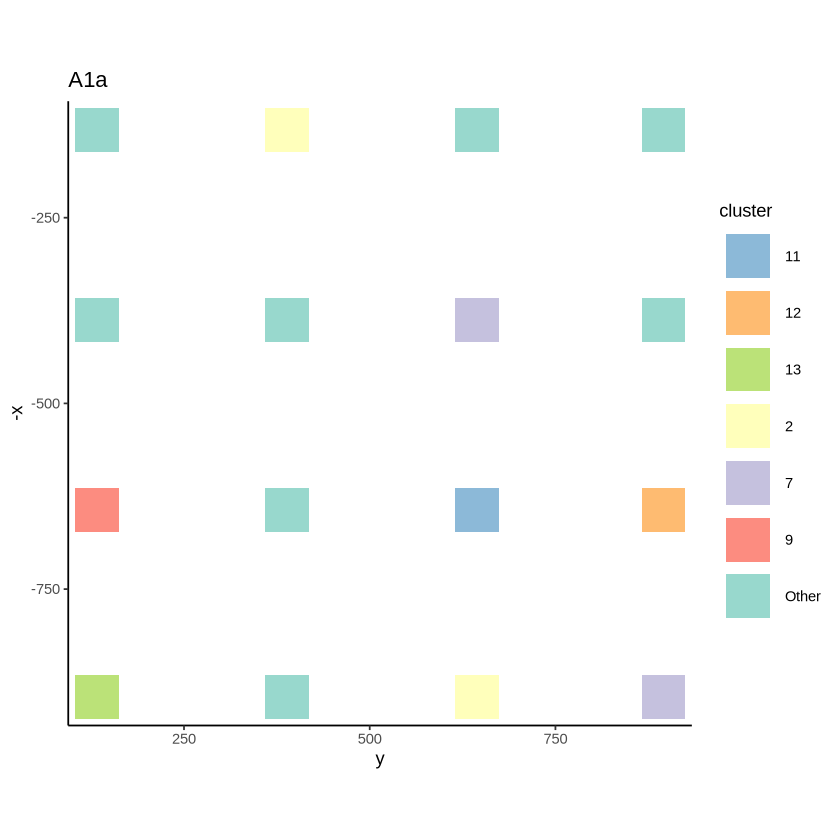

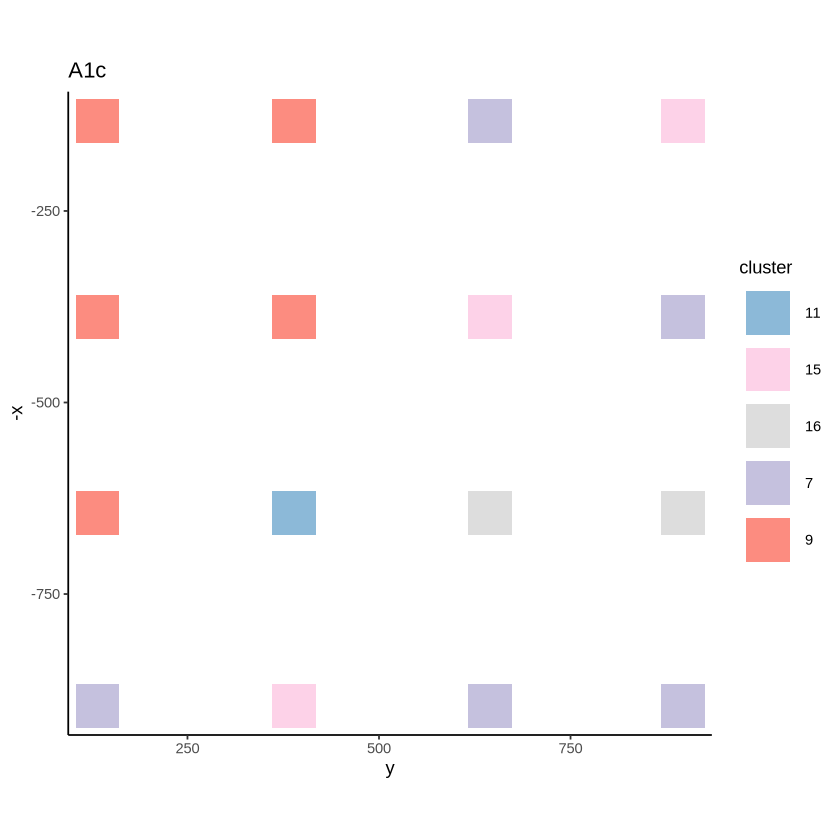

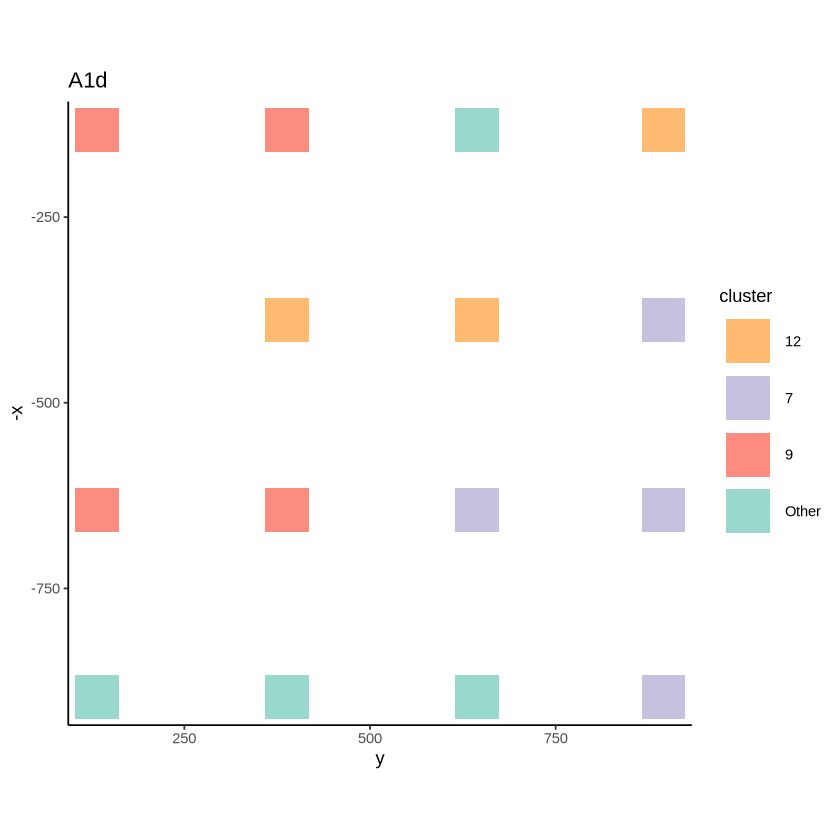

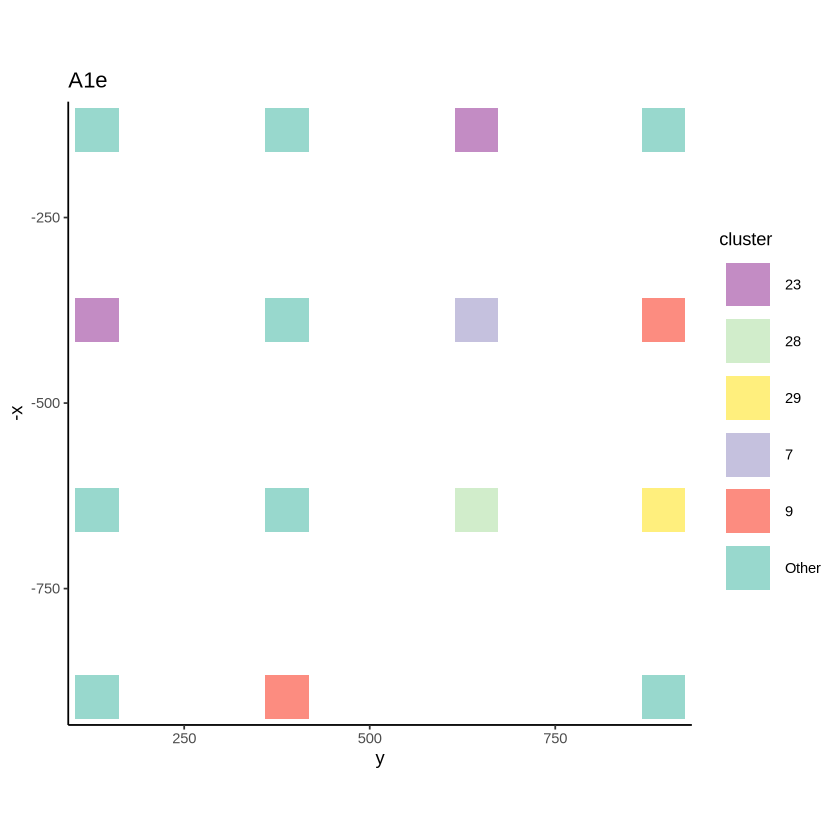

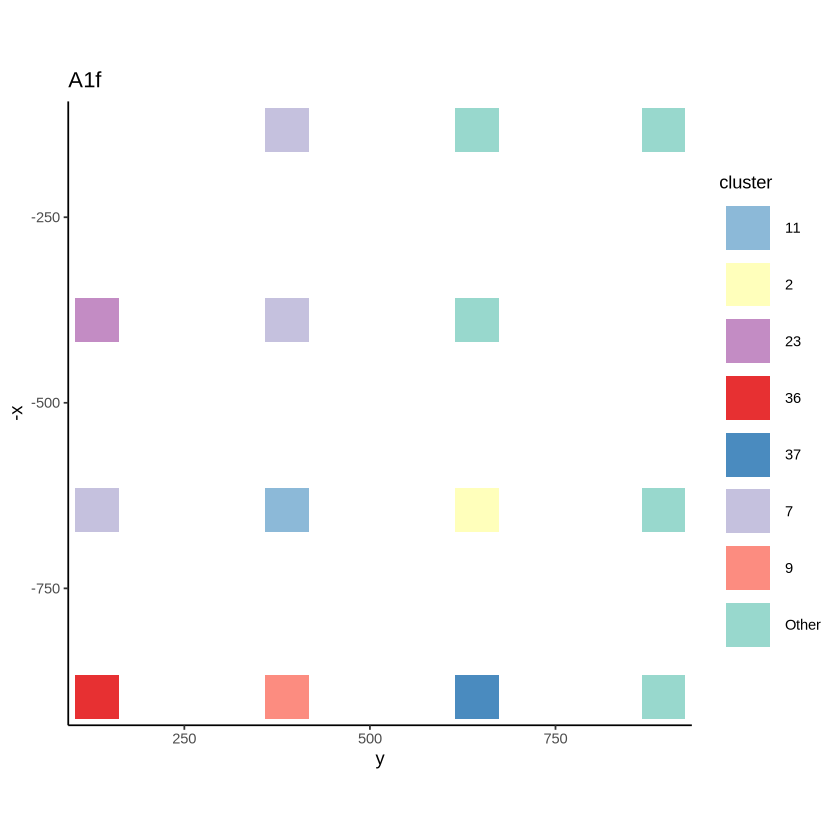

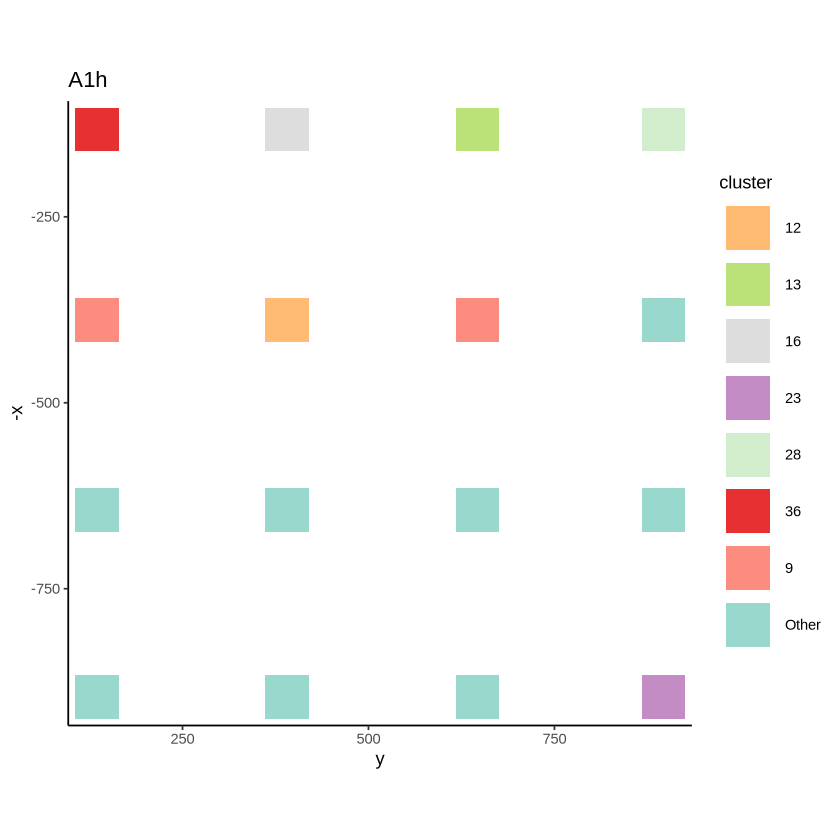

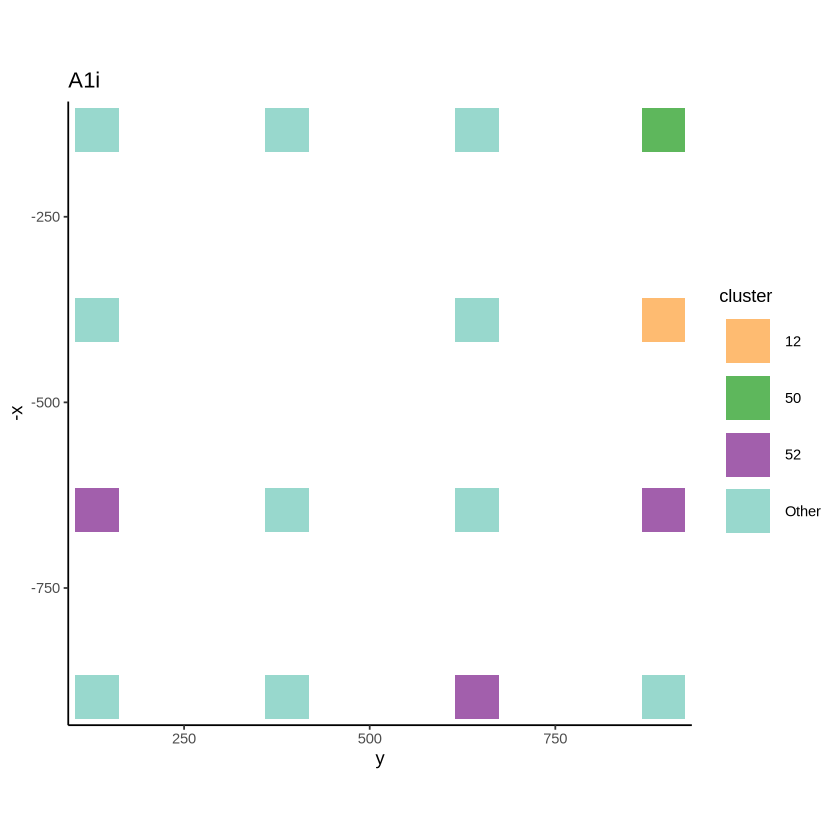

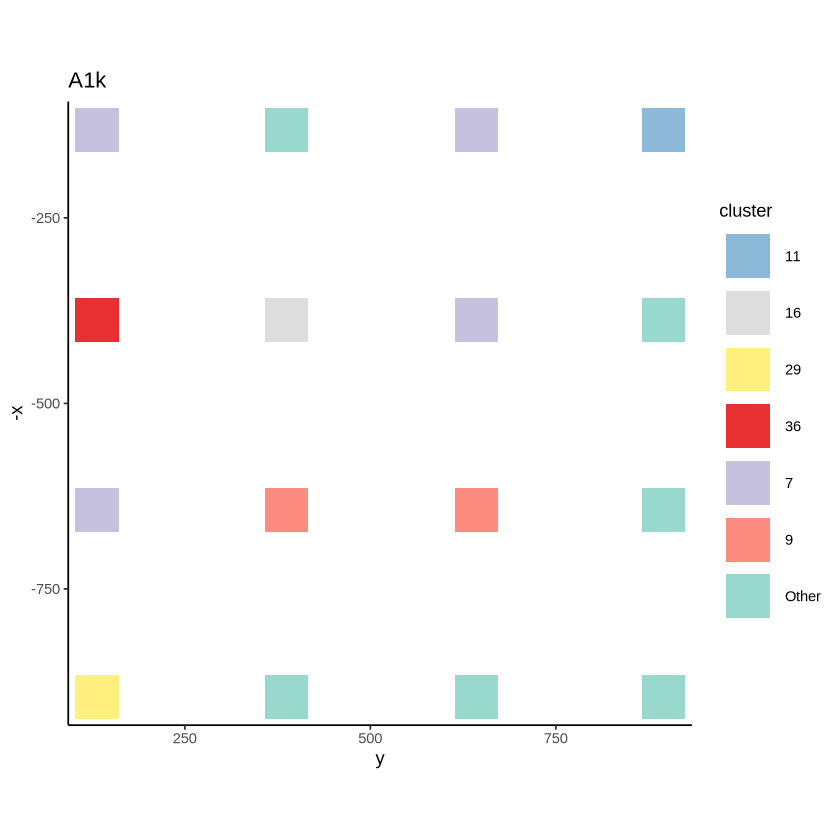

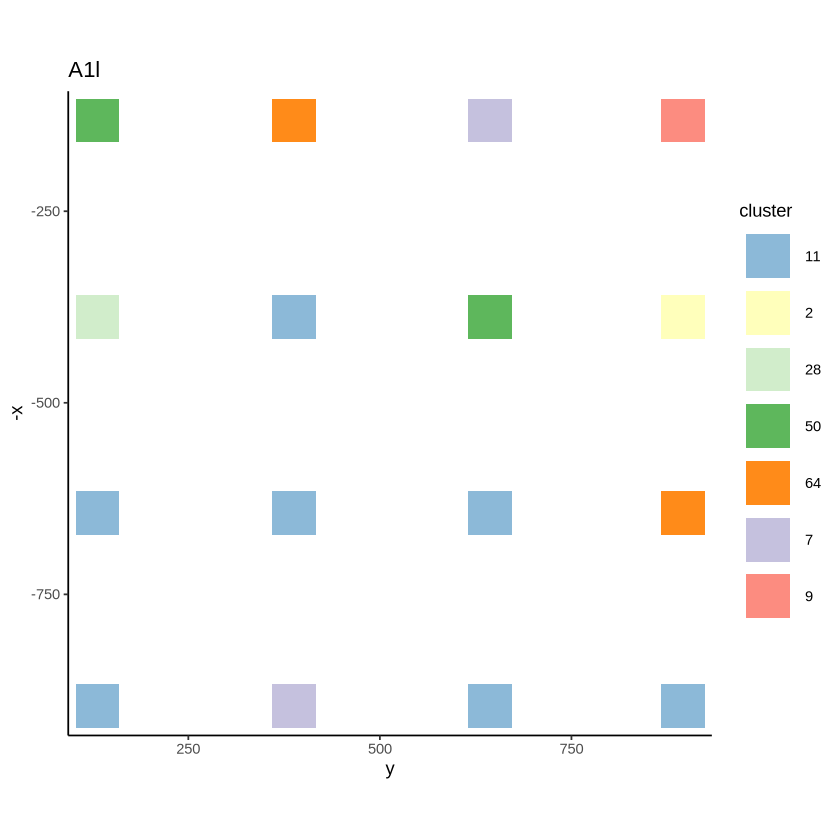

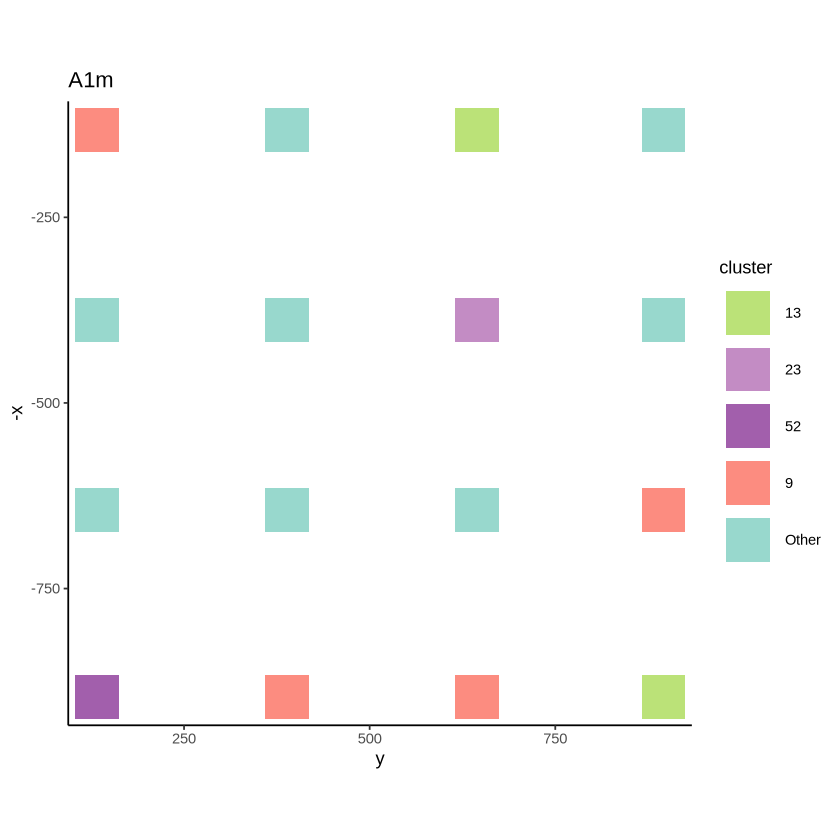

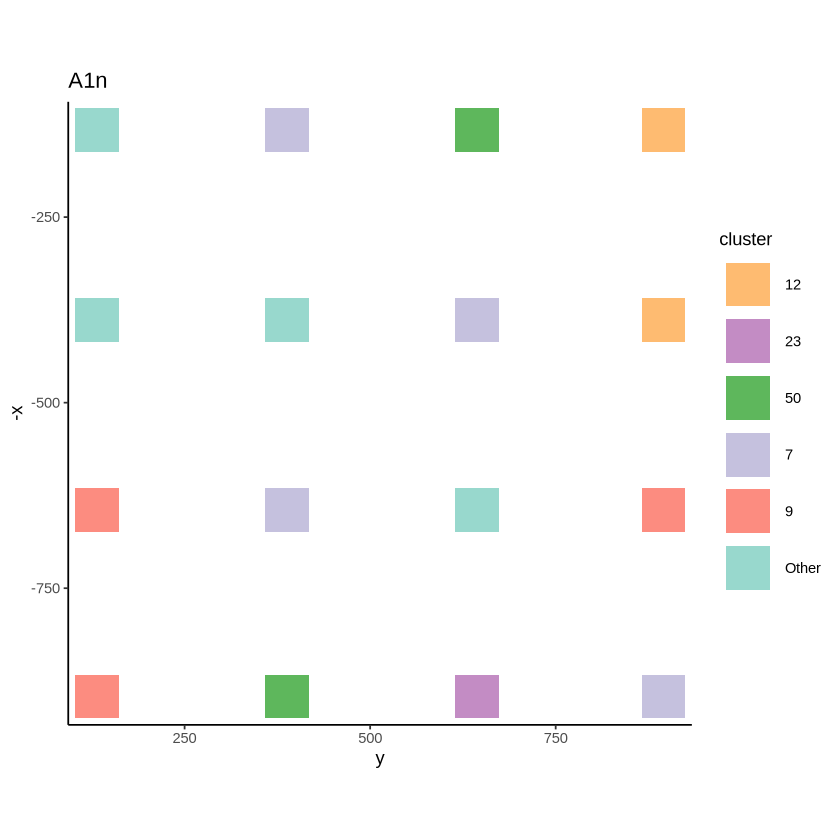

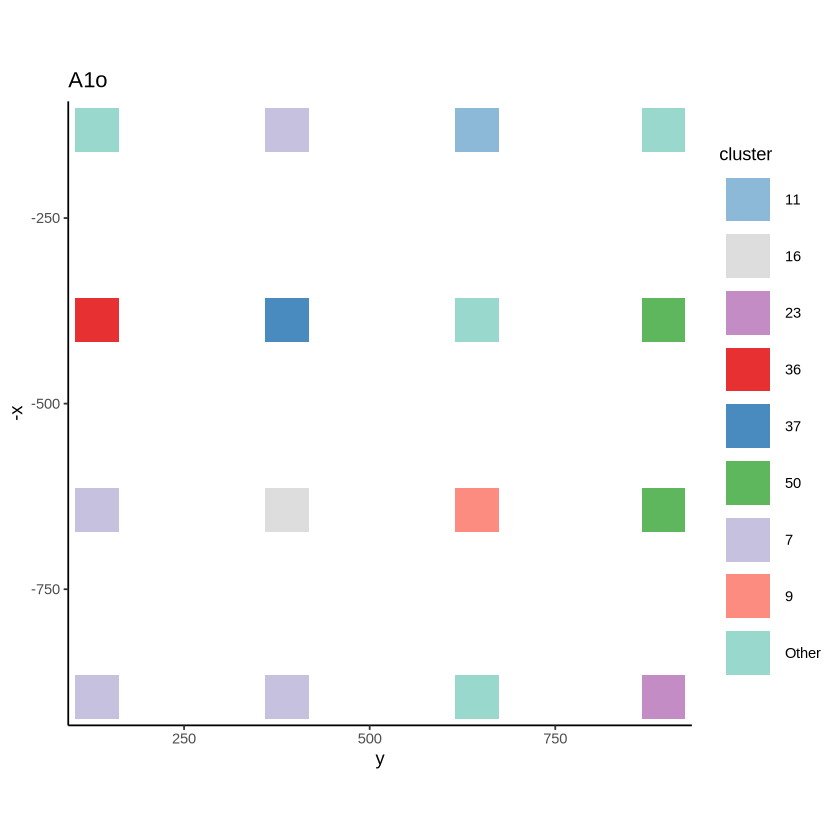

In [32]:
clusters_selected <- cluster_stats$label_selected %>% 
    na.omit %>% 
    as.numeric

# For each row in each tibble, find which column is true (which cluster the window belongs to)
window_cluster_summary <- sm.repr.ext %>% map(
    ~ .x %>%
    select(-id, -x, -y) %>%
    mutate(cluster = names(.)[max.col(.)] %>% str_remove(pattern = "...")) %>% 
    mutate(cluster = ifelse(cluster %in% clusters_selected, cluster, "Other")) %>%
    select(cluster)
)

# Add x and y coordinates from the original tibbles
window_cluster_summary <- map2(window_cluster_summary, sm.repr.ext, 
    ~ cbind(.x, .y %>% select(id, x, y)))

# Get unique values across the "cluster" columns of each tibble of the list
all_clust <- window_cluster_summary %>%
    map(~ .x$cluster) %>%  # Extract the "cluster" column from each tibble
    unlist() %>%           # Combine the lists into a single vector
    unique()               # Get the unique values

# palette <- brewer.pal(12, "Set3")
palette <- c(brewer.pal(12, "Set3"), brewer.pal(6, "Set1"))
# palette <- c(brewer.pal(12, "Set3"), brewer.pal(8, "Set2"), brewer.pal(6, "Set1"))

# Map a unique color to each cluster
cluster_colors <- setNames(palette, all_clust)

# Display the cluster of each window in each sample
# Plot title should be the first element of the "id" column
# Coordinates of each dot are in the "x" and "y" columns
# Color should be which one of the remaining columns has a "true" value
window_cluster_summary[1:12] %>% map(
    ~ ggplot(.x, aes(x = y, y = -x, color = cluster)) +
        geom_point(size = 12, shape = "square", alpha = 0.9) +
        theme_classic() +
        coord_fixed() +
        scale_color_manual(values = cluster_colors) +
        ggtitle(.x$id[1])
    ) %>% walk(print)

Cluster @ 0.35/0.35: 15 = background panCK + bit of SMA + bit of CD31 + lots of SMA. Consistent, yet defined from metabolic markers alone.

### Compare frequency per stage

In [33]:
sm.repr %>% 
    select(-id) %>% 
    # Convert to boolean (is > 0)
    mutate(across(everything(), ~ .x > 0)) %>%
    # Sum up
    colMeans

...2      ...7      ...9     ...11     ...12     ...13     ...15     ...16 
0.1914894 0.6737589 0.6666667 0.1938534 0.2056738 0.3120567 0.1229314 0.1631206 
    ...23     ...28     ...29     ...36     ...37     ...50     ...52     ...64 
0.4822695 0.1229314 0.1252955 0.1442080 0.1347518 0.2718676 0.1111111 0.1489362 
    ...89 
0.1205674

In [34]:
# Get first "Stage" per "fov"
stages <- cells %>% 
    group_by(fov) %>%
    summarize(stage = first(Stage))
# Join cluster frequencies with stages
sm.repr.stage <- sm.repr %>%
    left_join(stages, join_by(id == fov))
# Rename columns
sm.repr.stage <- sm.repr.stage %>% 
    rename_with(~ paste0("Cluster", str_remove(.x, "...")), starts_with("..."))

pal_stages <- c(rgb(127,201,127,maxColorValue=255),
                rgb(242,240,247,maxColorValue=255),
                rgb(203,201,226,maxColorValue=255),
                rgb(158,154,201,maxColorValue=255),
                rgb(106,81,163,maxColorValue=255))


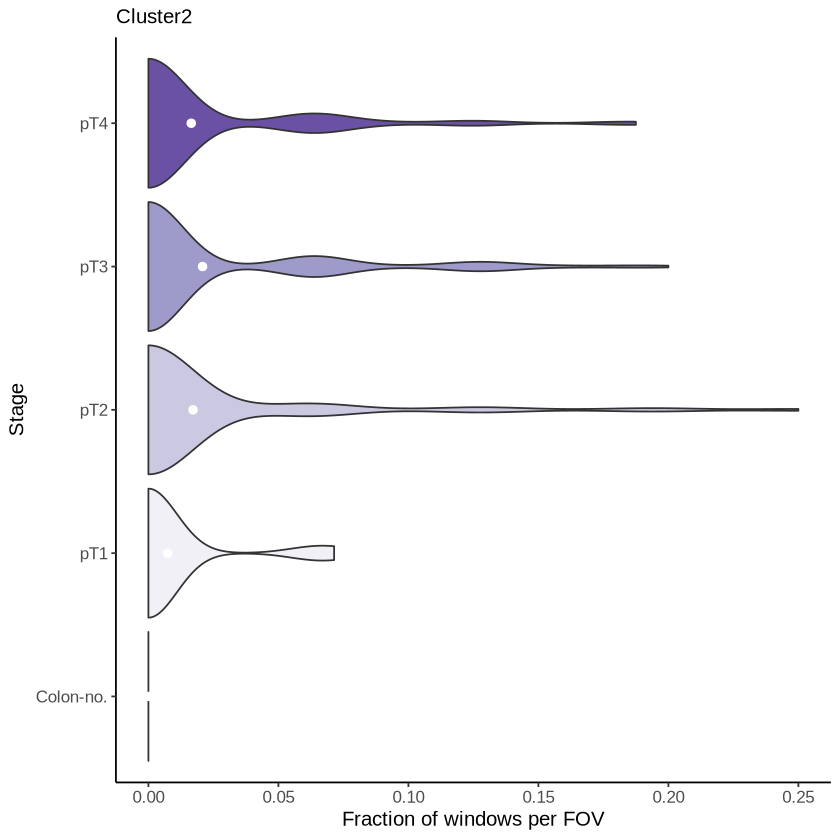

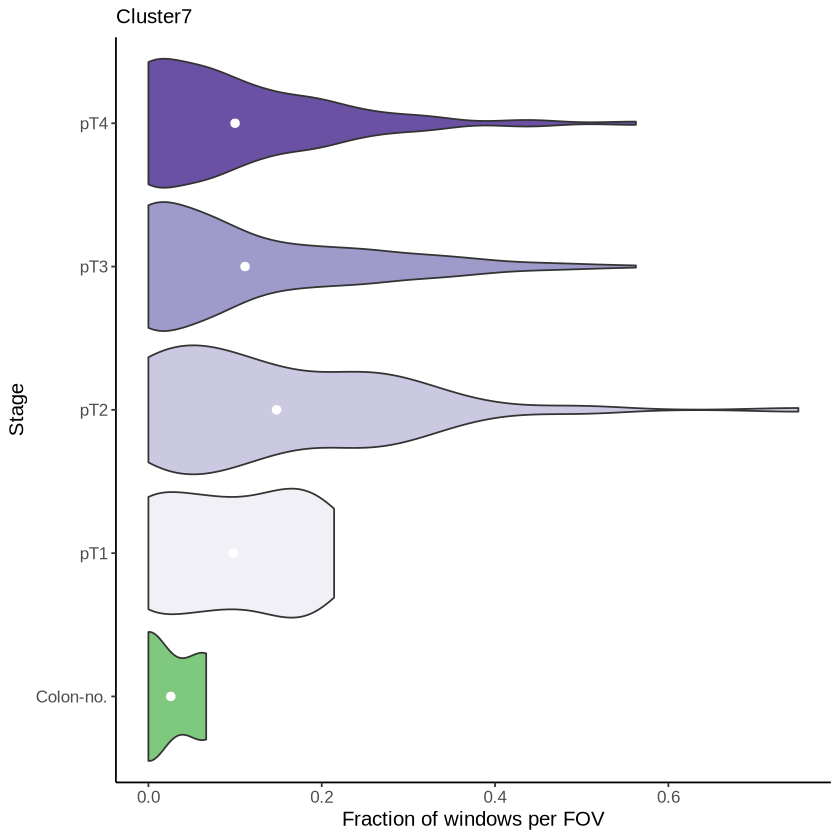

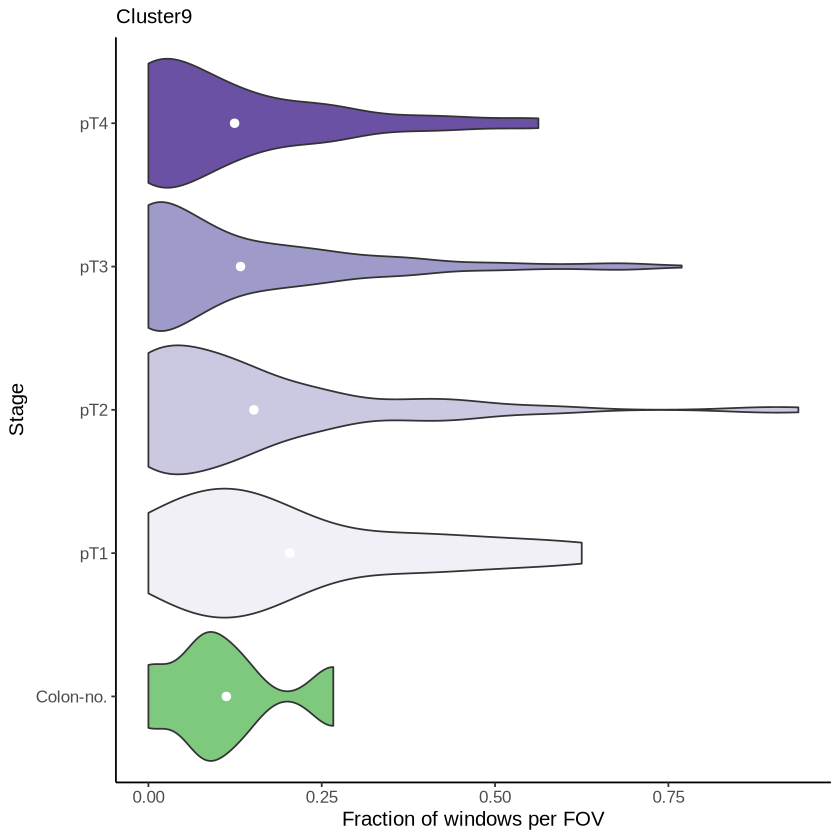

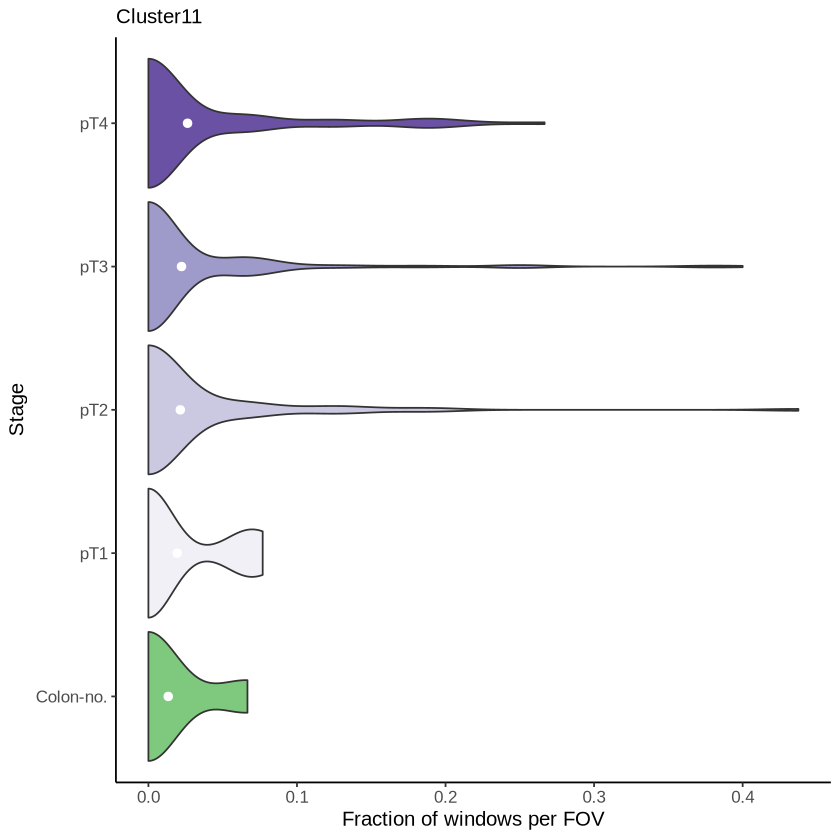

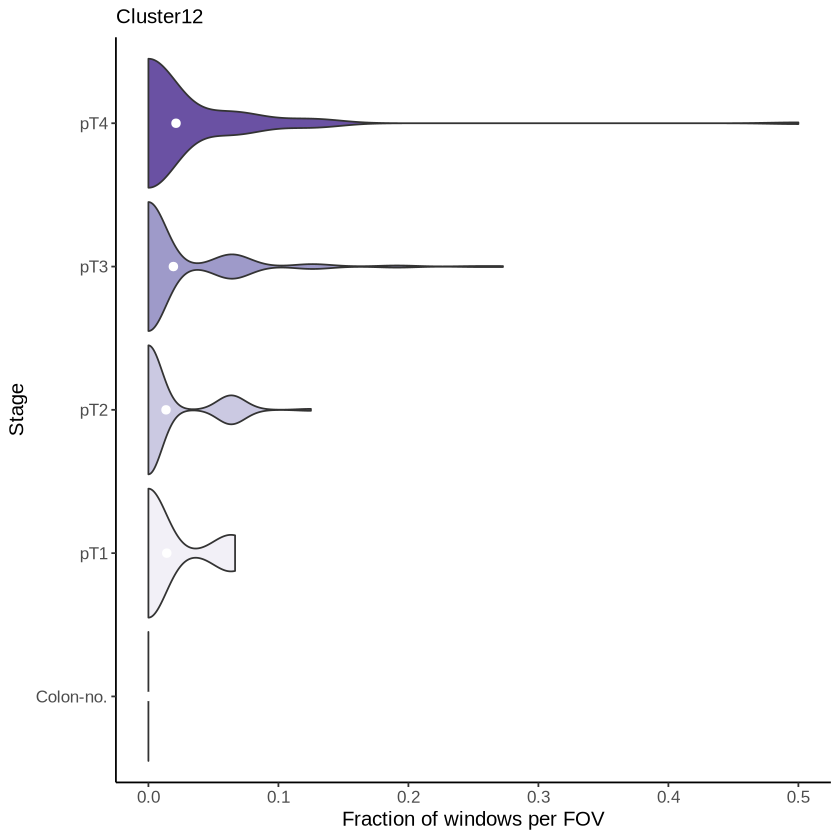

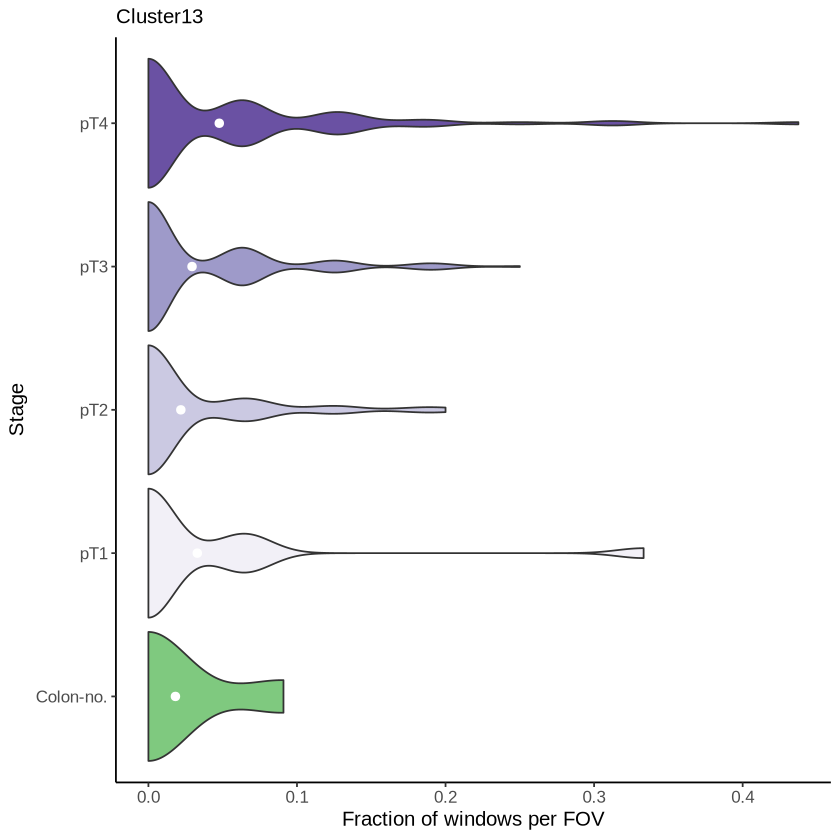

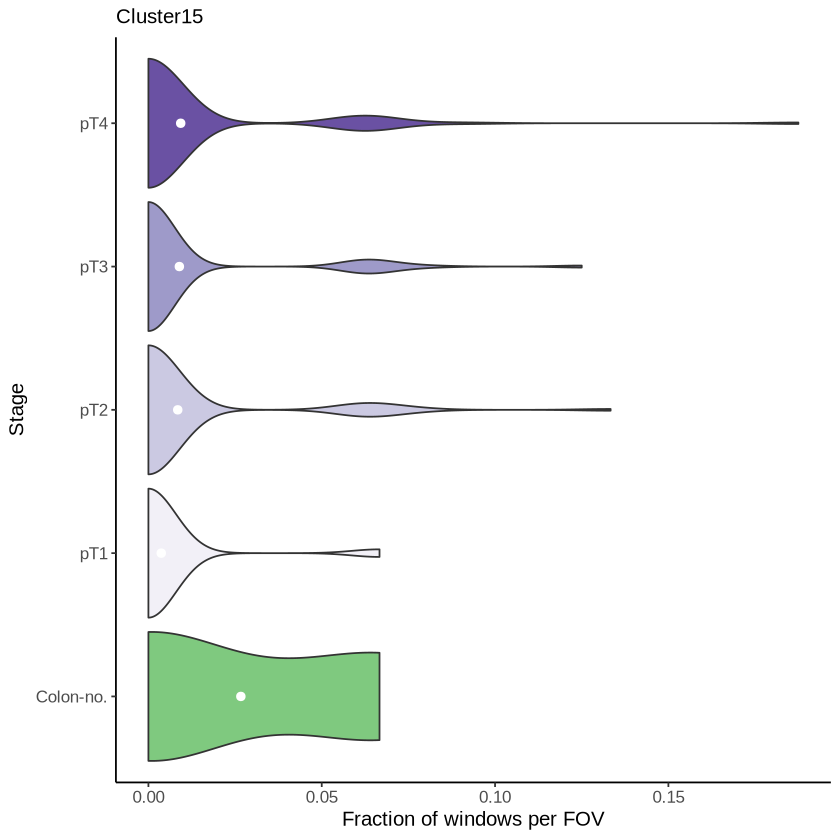

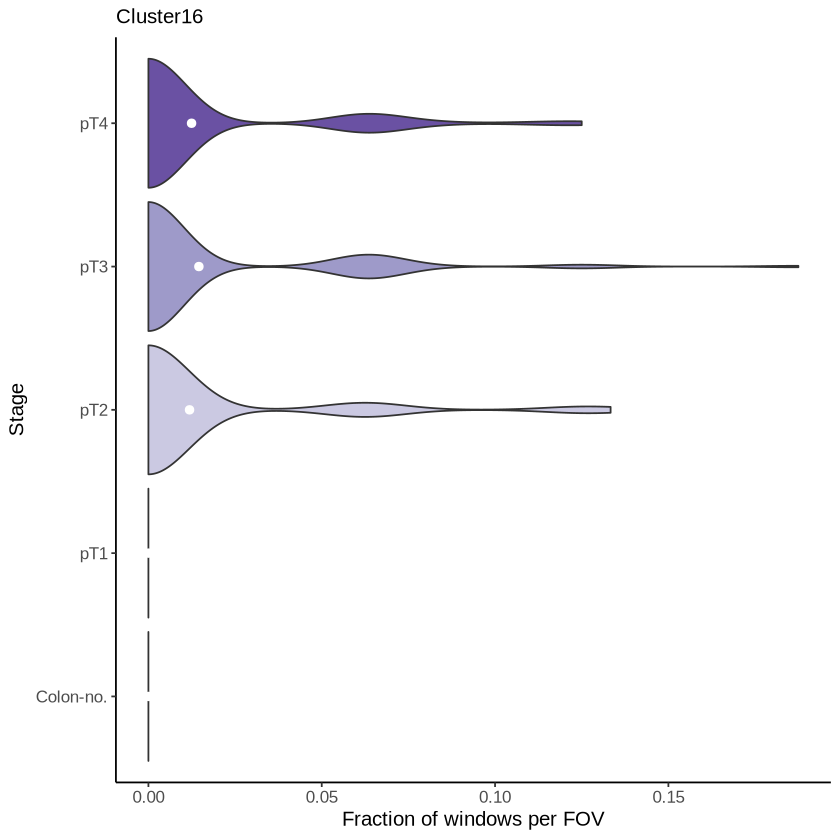

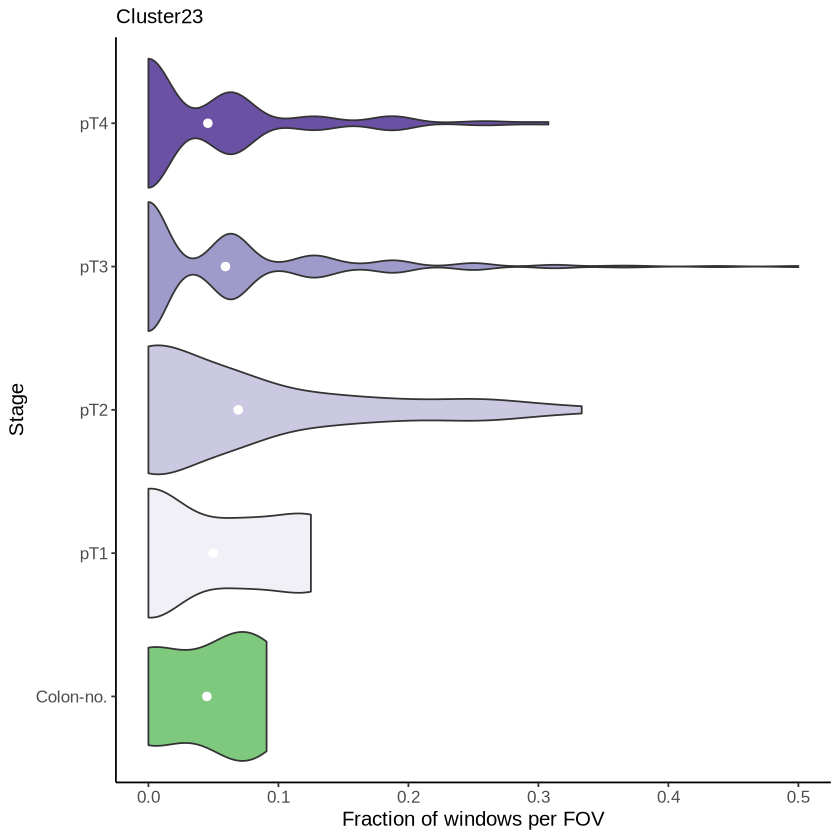

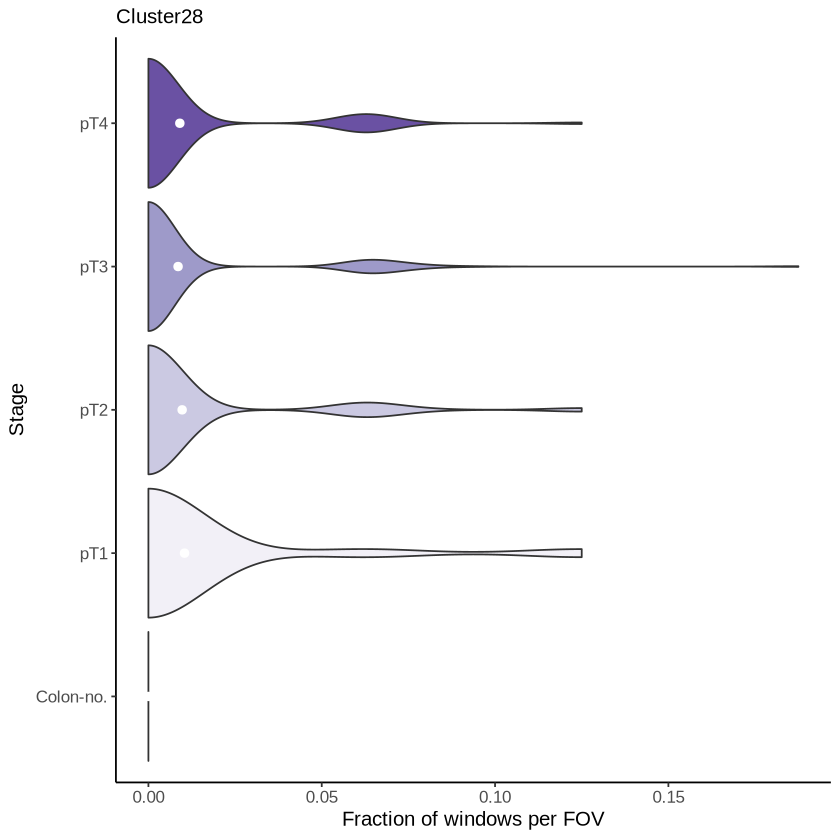

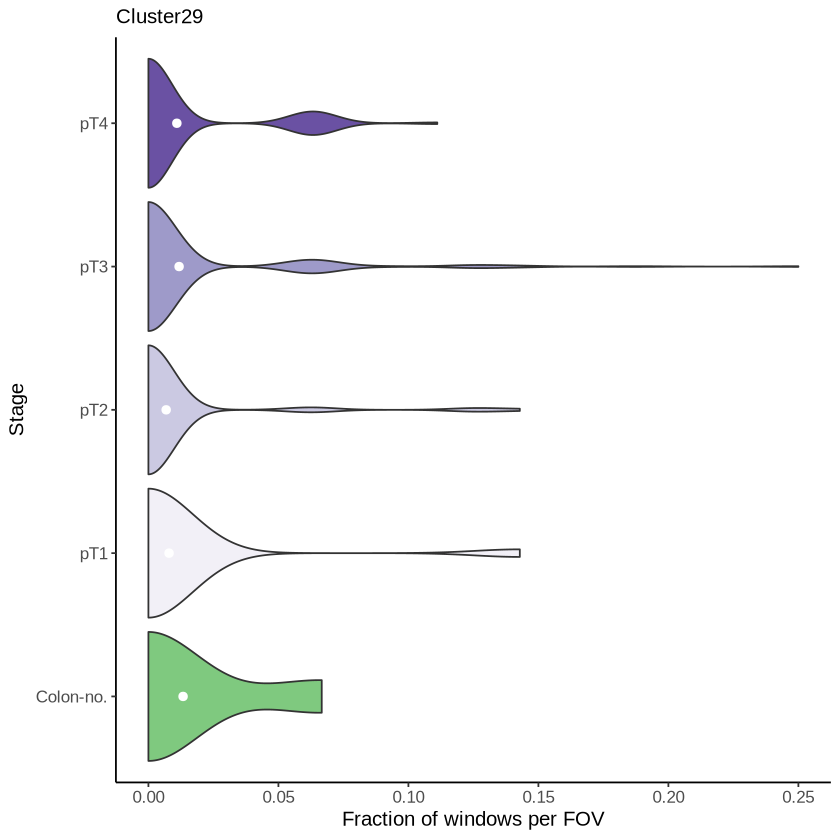

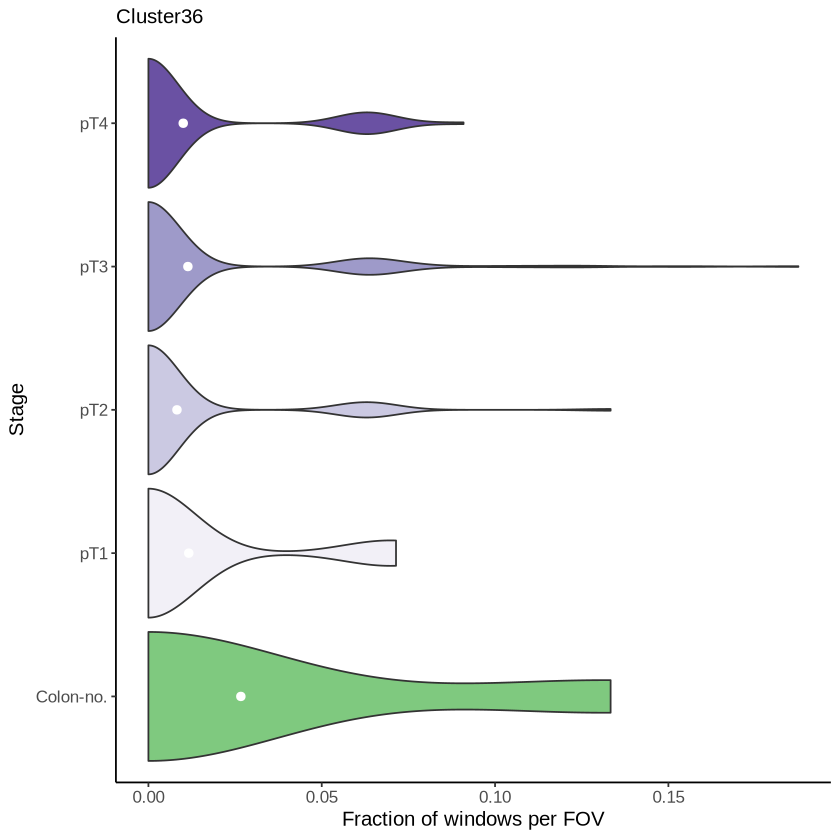

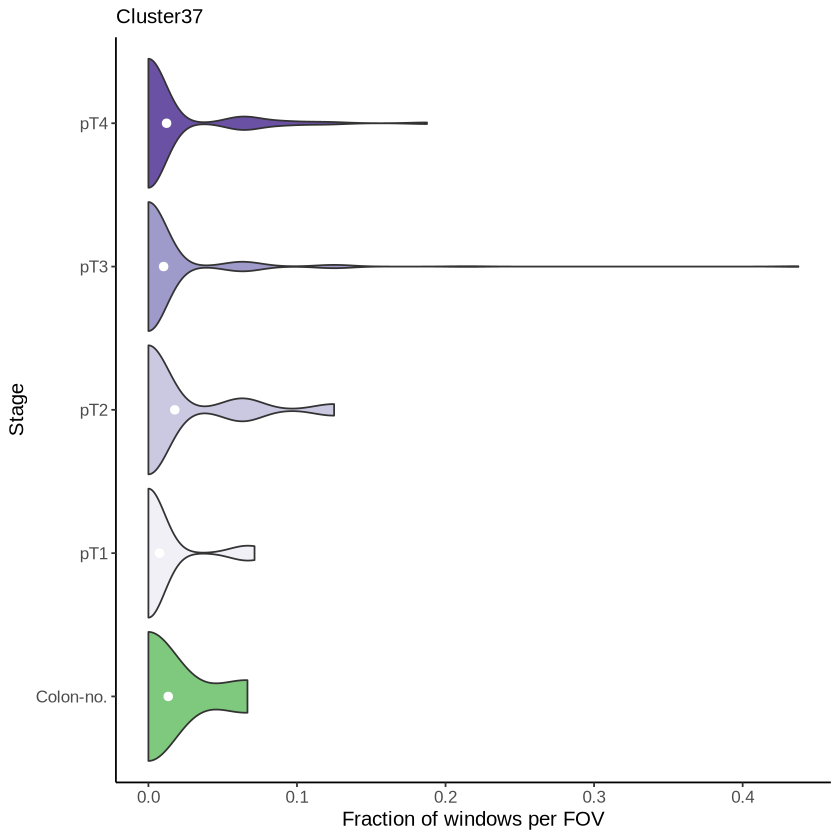

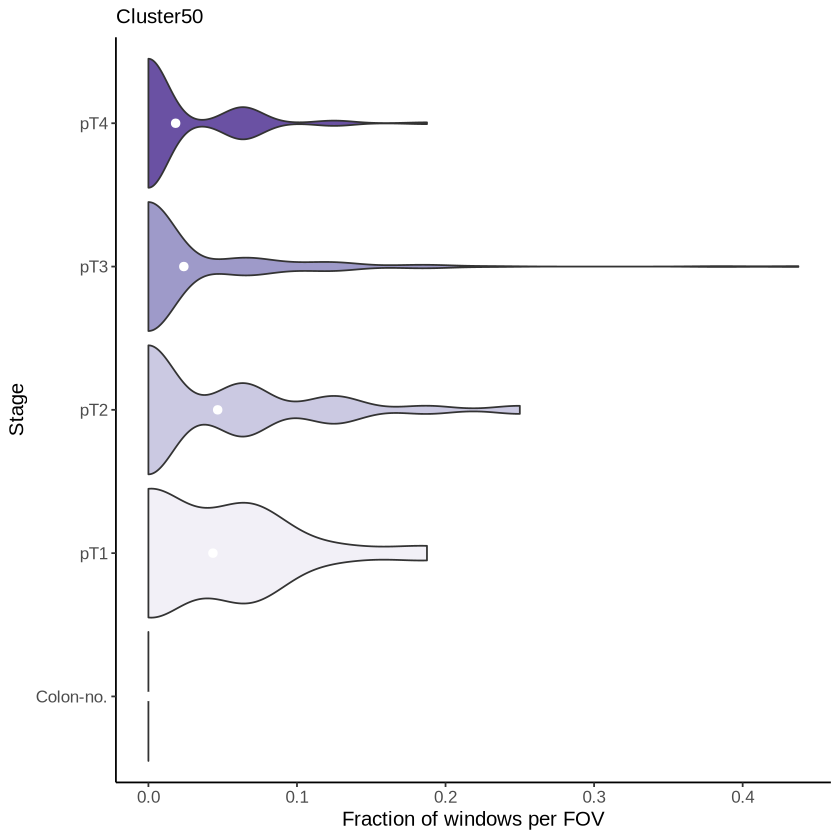

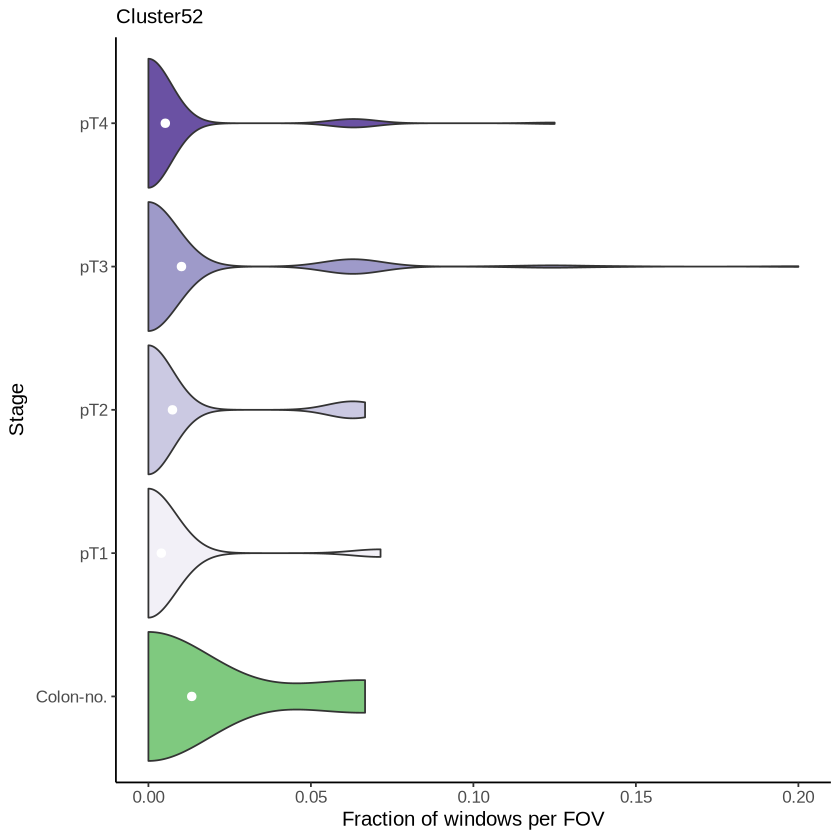

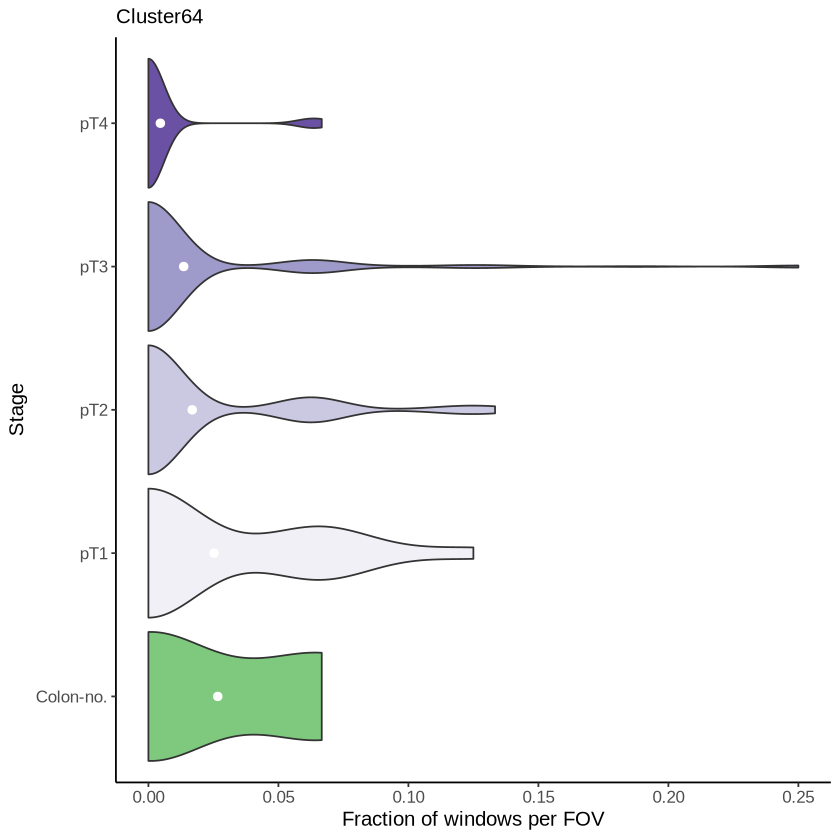

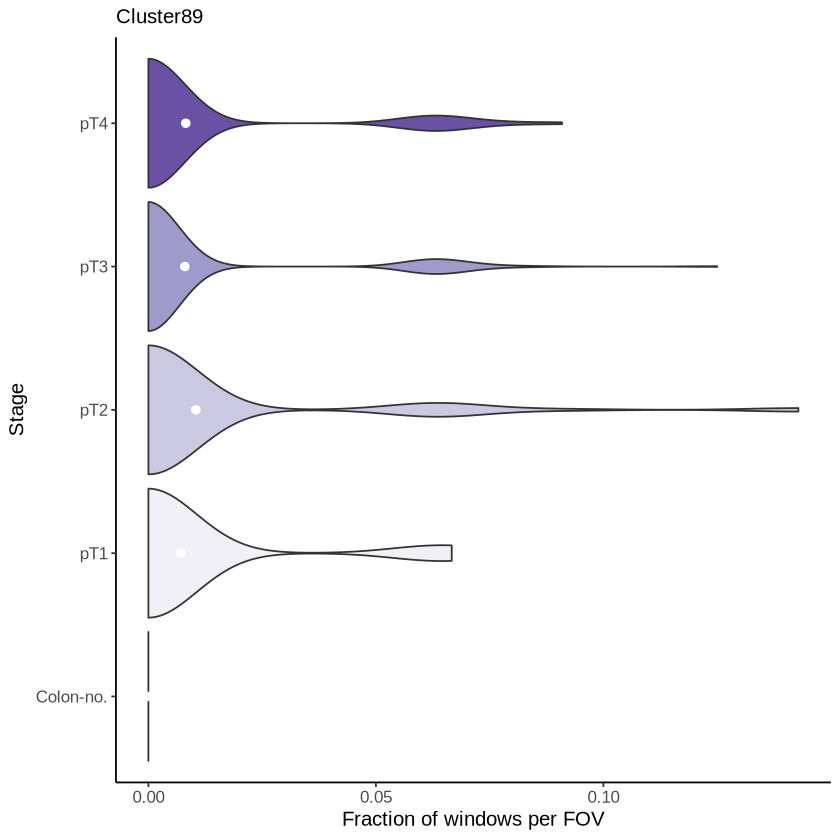

In [35]:
# All columns except "id" and "stage"
layout_scale <- 0.49  # Fig S7j is placed at 49% of its saved size
top_clust <- names(sm.repr.stage)

for (cluster_plot in top_clust[!(top_clust %in% c("id", "stage"))]){
    gp <- (ggplot(sm.repr.stage, aes(y = !!sym(cluster_plot), x = stage, fill = stage))
        + geom_violin(scale="width")
        + theme_classic()
        + coord_flip()
        + stat_summary(fun=mean, geom='point', color='white', size=2)
        + scale_fill_manual(values = pal_stages)
        + ggtitle(cluster_plot)
        + paper_theme(layout_scale)
        + theme(legend.position = "none")
        + xlab("Stage") + ylab("Fraction of windows per FOV")
    )
    print(gp)
    # Export plots for selected clusters
    if (cluster_plot %in% c("Cluster7", "Cluster11")) {
        ggsave(filename = paste0("../../figures/fig4/kasumi_", cluster_plot, ".pdf"), 
               plot = gp, width = 4, height = 2, dpi = 300)
    }
}

In [36]:
sm.repr.stage %>% 
    group_by(stage) %>%
    slice_max(order_by = Cluster11, n = 3) %>%
    select(id, stage, Cluster11)

id,stage,Cluster11
<chr>,<chr>,<dbl>
E4a,Colon-no.,0.06666667
E3c,Colon-no.,0.00000000
E3e,Colon-no.,0.00000000
E4d,Colon-no.,0.00000000
E4e,Colon-no.,0.00000000
B5g,pT1,0.07692308
A1f,pT1,0.07142857
C9h,pT1,0.07142857
A1l,pT2,0.43750000


In [37]:
sm.repr.stage %>% 
    group_by(stage) %>%
    slice_max(order_by = Cluster7, n = 3) %>%
    select(id, stage, Cluster7)

id,stage,Cluster7
<chr>,<chr>,<dbl>
E3c,Colon-no.,0.06666667
E4e,Colon-no.,0.06250000
E3e,Colon-no.,0.00000000
E4a,Colon-no.,0.00000000
E4d,Colon-no.,0.00000000
A1f,pT1,0.21428571
A5f,pT1,0.18750000
C1i,pT1,0.18750000
D2k,pT1,0.18750000


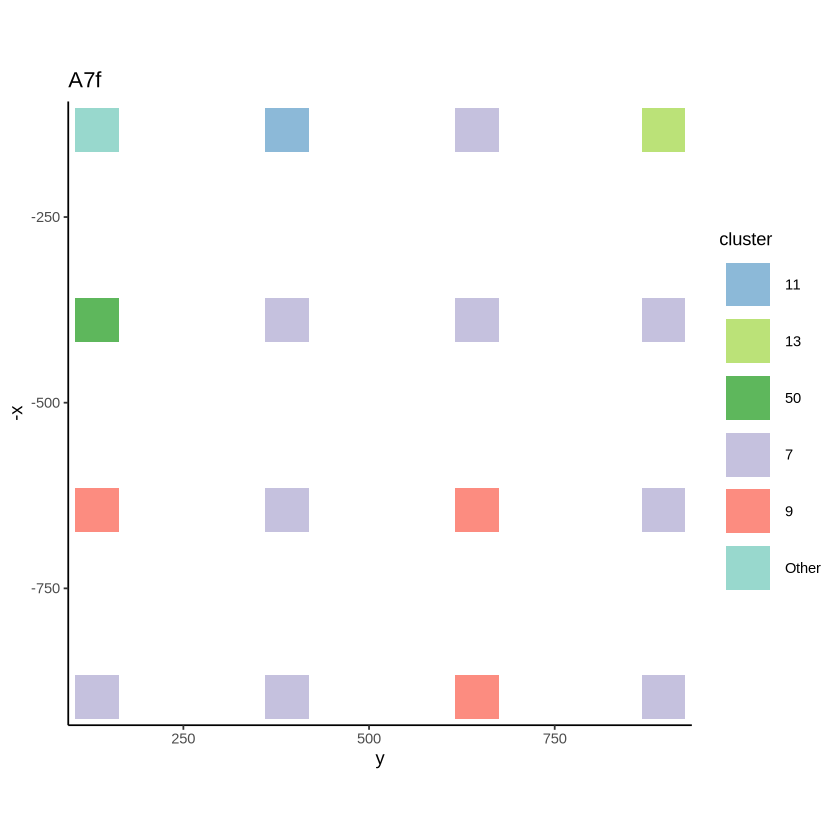

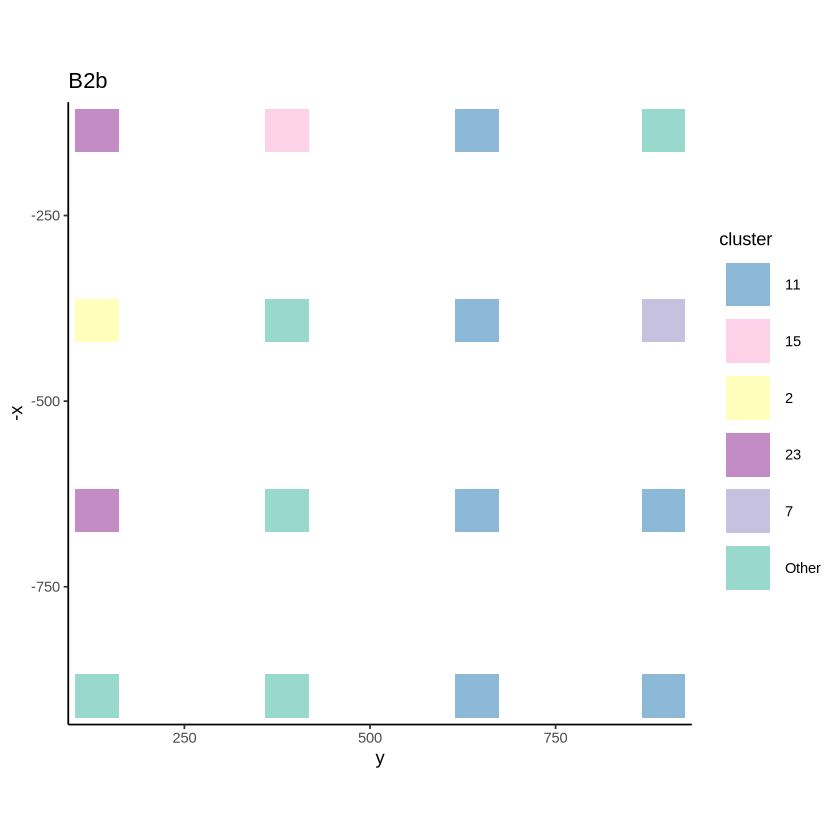

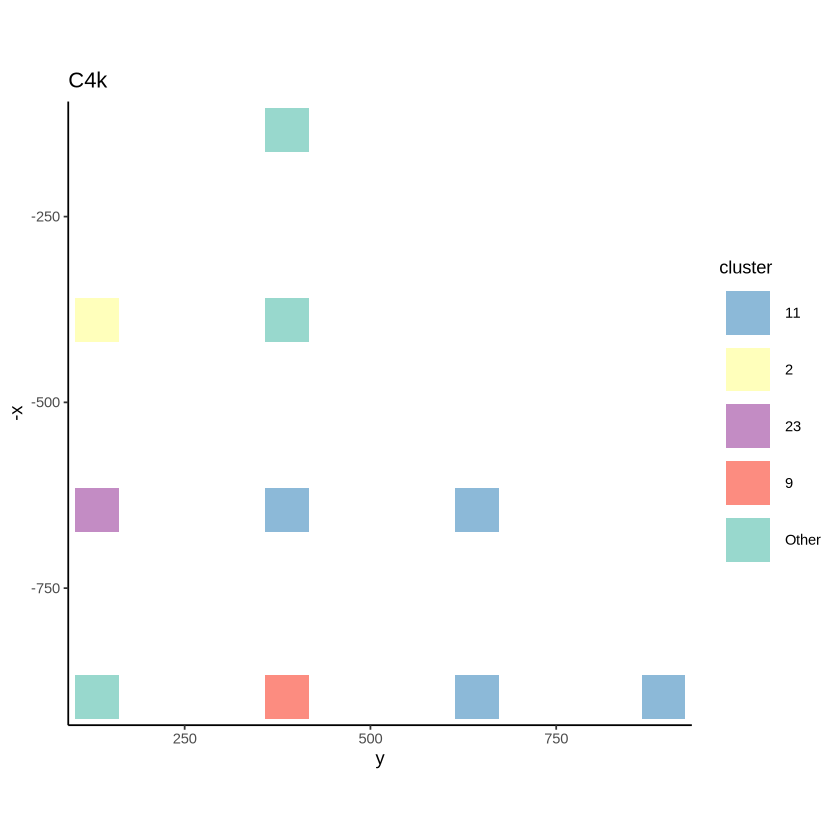

In [38]:
window_cluster_summary[sm.repr.stage$id %in% c("B2b", "C4k", "A7f")] %>% map(
    ~ ggplot(.x, aes(x = y, y = -x, color = cluster)) +
        geom_point(size = 12, shape = "square", alpha = 0.9) +
        theme_classic() +
        coord_fixed() +
        scale_color_manual(values = cluster_colors) +
        ggtitle(.x$id[1])
    ) %>% walk(print)

In [39]:
library(DBI)
library(RSQLite)
library(dplyr)

describe_cluster <- function(sm.repr, cluster, db.file) {
  cname <- paste0("...", cluster)
  sm.repr.all <- reduce(sm.repr, rbind)
  left <- sm.repr.all %>%
    filter(if_any(!!cname)) %>%
    select(id, x, y)

  dbcon <- dbConnect(RSQLite::SQLite(), db.file)
  samples <- dbGetQuery(dbcon, "SELECT DISTINCT sample FROM contributions") %>% unlist()
  matching <- grep(paste0("(", paste0(unique(left$id), collapse = "|"), ")"), samples, value = TRUE)
  dbDisconnect(dbcon)

  right <- tibble(sample = matching) %>%
    mutate(
      id = str_extract(sample, ".*/") %>% str_remove("/"),
      box = str_extract(sample, "/[0-9].*$") %>% str_remove("/")
    ) %>%
    rowwise(id) %>%
    summarize(sample = sample, rebox = box %>%
      str_split("_", simplify = T) %>%
      as.numeric() %>% list(), .groups = "drop") %>%
    rowwise(id) %>%
    summarize(
      sample = sample,
      xcenter = (rebox[3] + rebox[1]) / 2,
      ycenter = (rebox[4] + rebox[2]) / 2, .groups = "drop"
    )

  pattern <- paste0("(", paste0(left %>%
    left_join(right, by = c("id", "x" = "xcenter", "y" = "ycenter")) %>%
    pull(sample), collapse = "|"), ")")

  collect_results(db.file, pattern)
}

### Describe a stage-specific cluster

In [40]:
cluster_specific <- describe_cluster(sm.repr.ext, 11, outputfile)








Aggregating



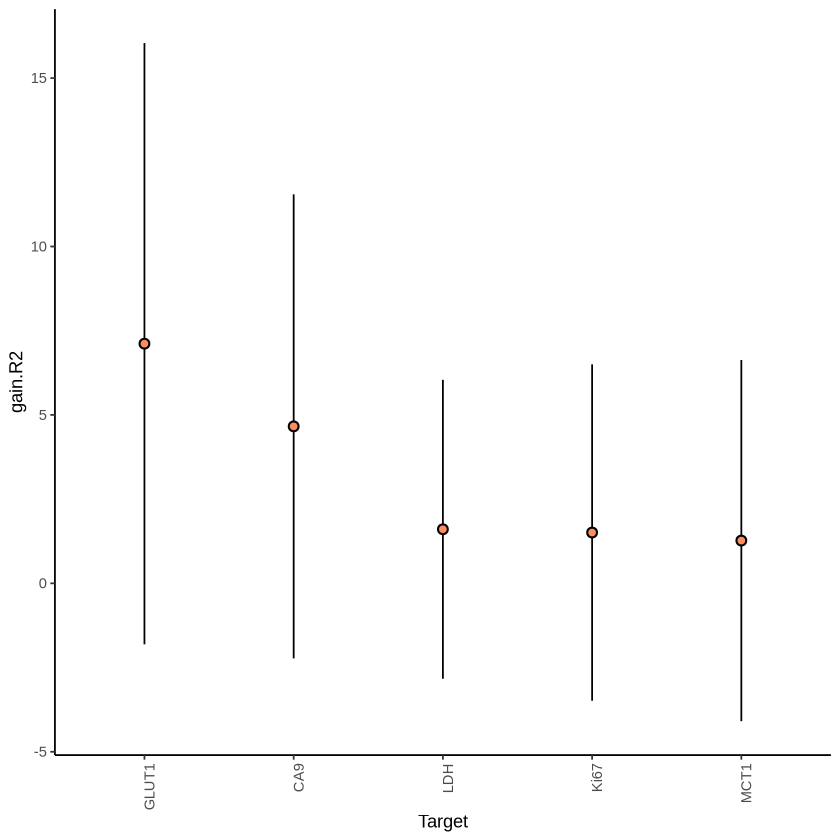

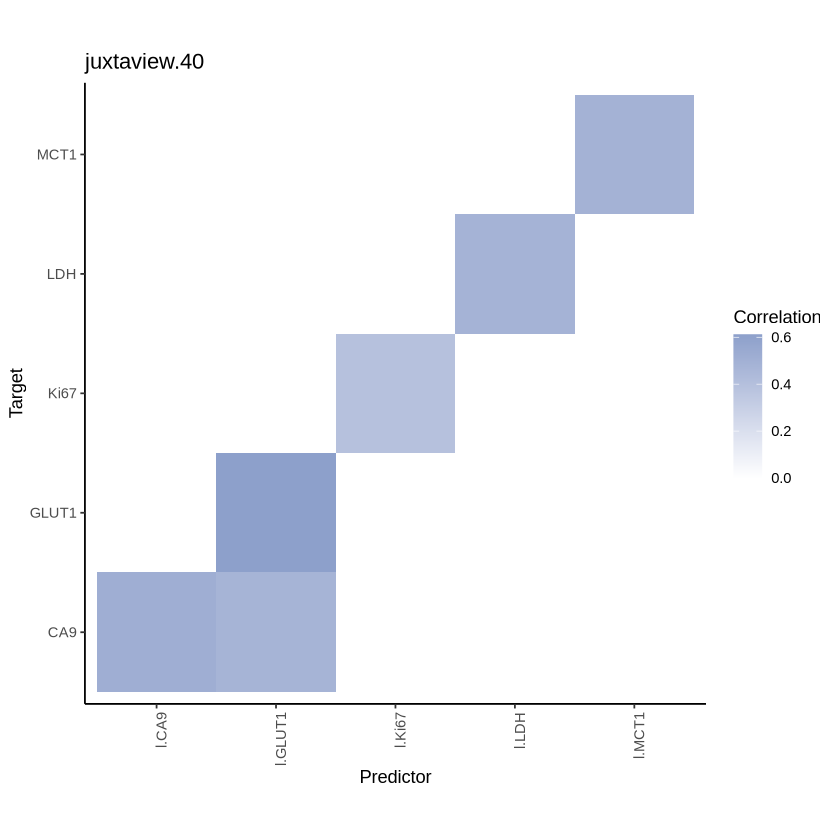

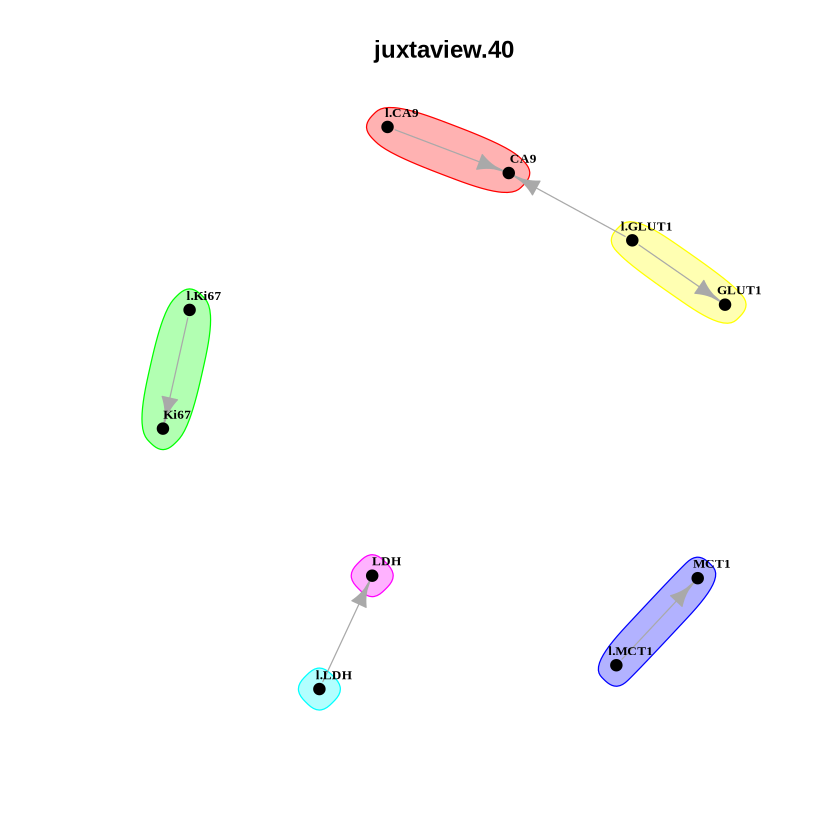

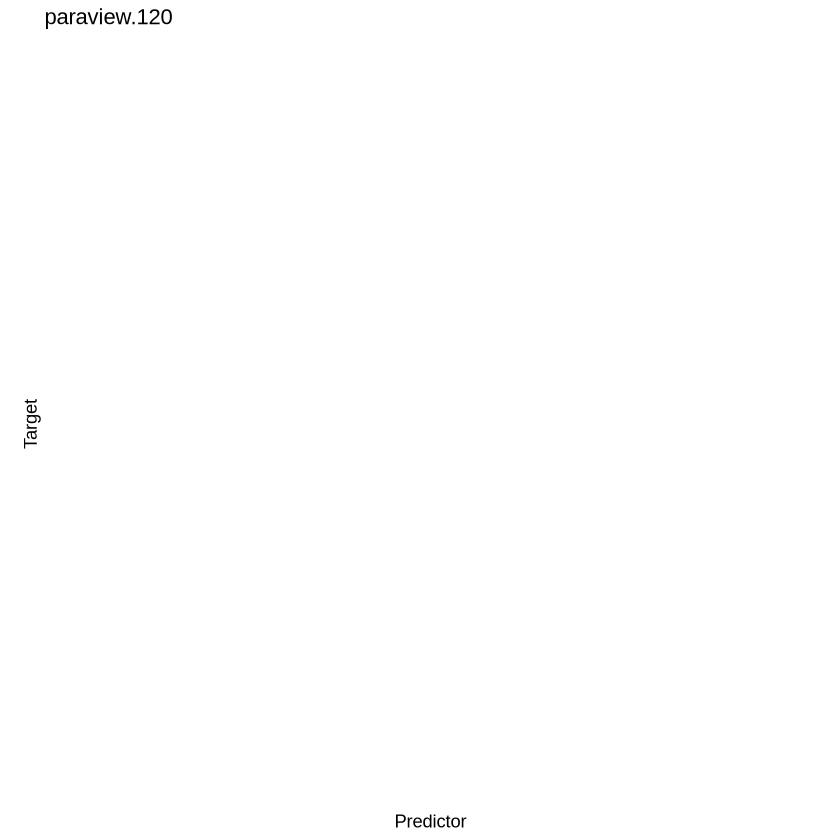

In [41]:
# Note: intraview is not used to define clusters
# plot_improvement_stats(cluster15, measure = "intra.R2", trim = c_trim)
layout_scale <- 0.475  # Fig 4k is placed at 47.5% of its saved size
plot_improvement_stats(cluster_specific, measure = "gain.R2", trim = c_trim)
ggsave(filename = "../../figures/fig4/kasumi_cluster_specific_gain.pdf",
       plot = last_plot() + paper_theme(layout_scale), width = 2, height = 3)
# plot_interaction_heatmap(cluster15, "intraview", clean = TRUE, correlation = TRUE, trim = c_trim, cutoff = c_cutoff)
plot_interaction_heatmap(cluster_specific, "juxtaview.40", clean = TRUE, correlation = TRUE, trim = c_trim, 
    cutoff = c_cutoff)
plot_interaction_communities(cluster_specific, view = "juxtaview.40", 
    trim = c_trim, cutoff = c_cutoff,
    path = "../../data/kasumi_cluster_specific_juxtaview.graphml")
plot_interaction_heatmap(cluster_specific, "paraview.120", clean = TRUE, correlation = TRUE, trim = c_trim, 
    cutoff = c_cutoff)

### Describe a common cluster

In [42]:
cluster_common <- describe_cluster(sm.repr.ext, 7, outputfile)








Aggregating



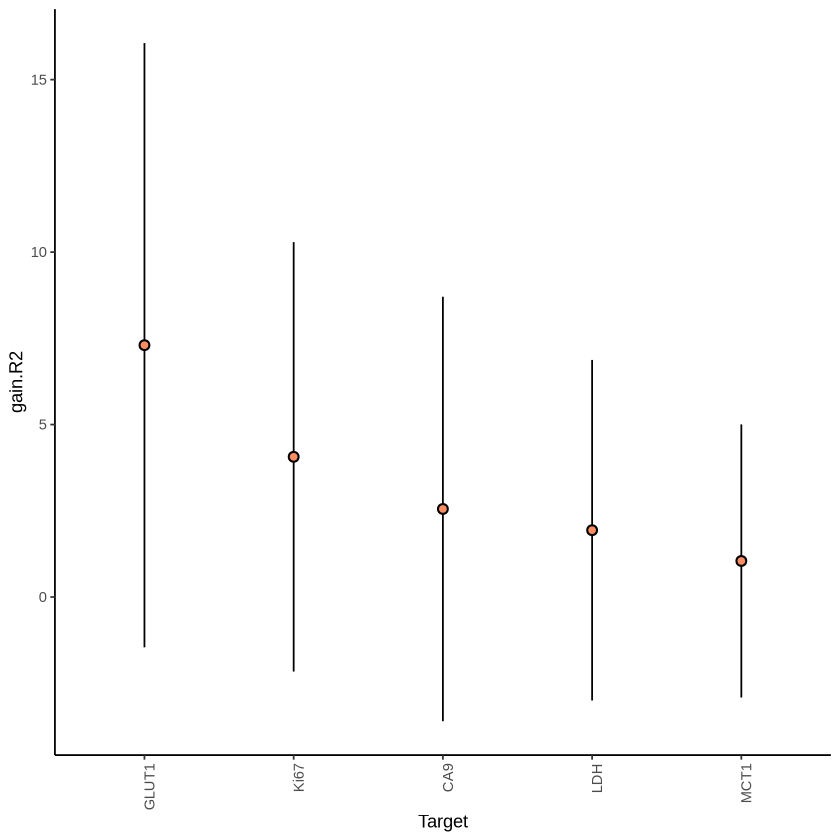

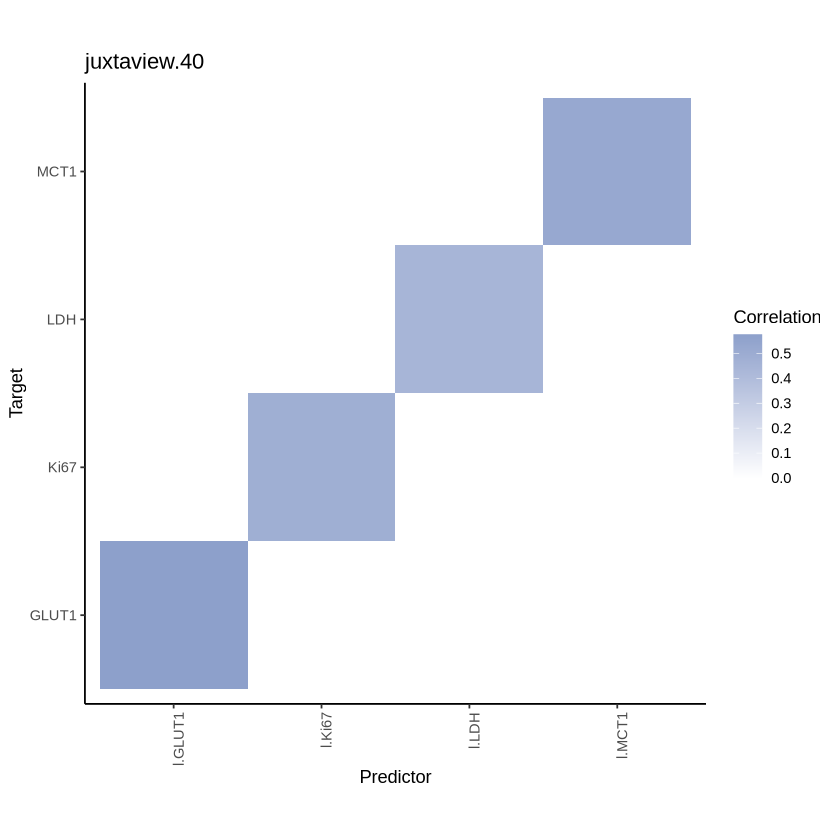

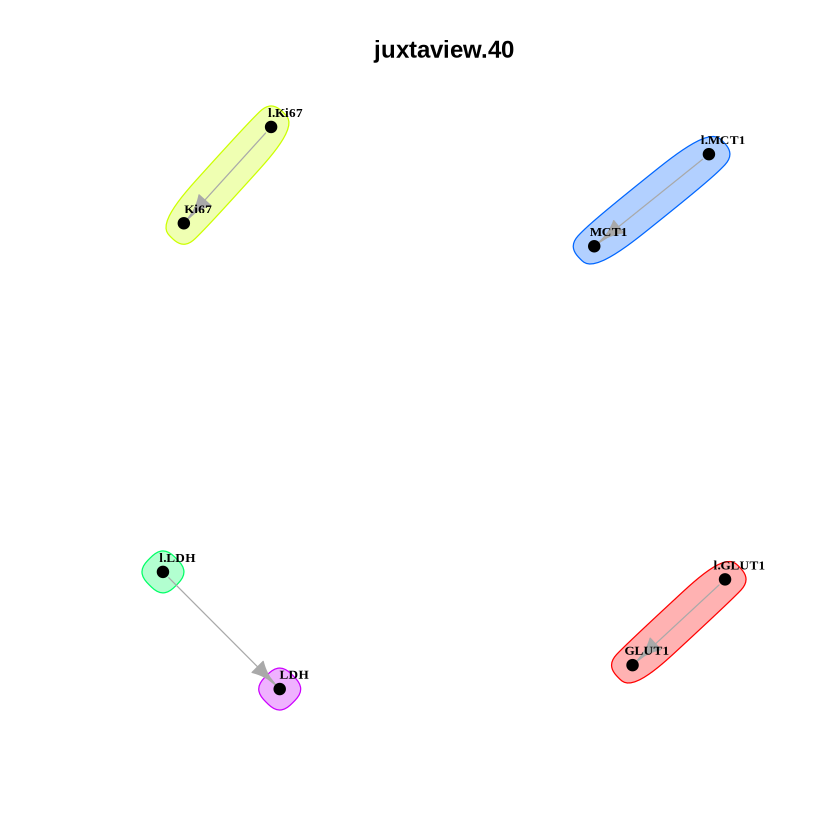

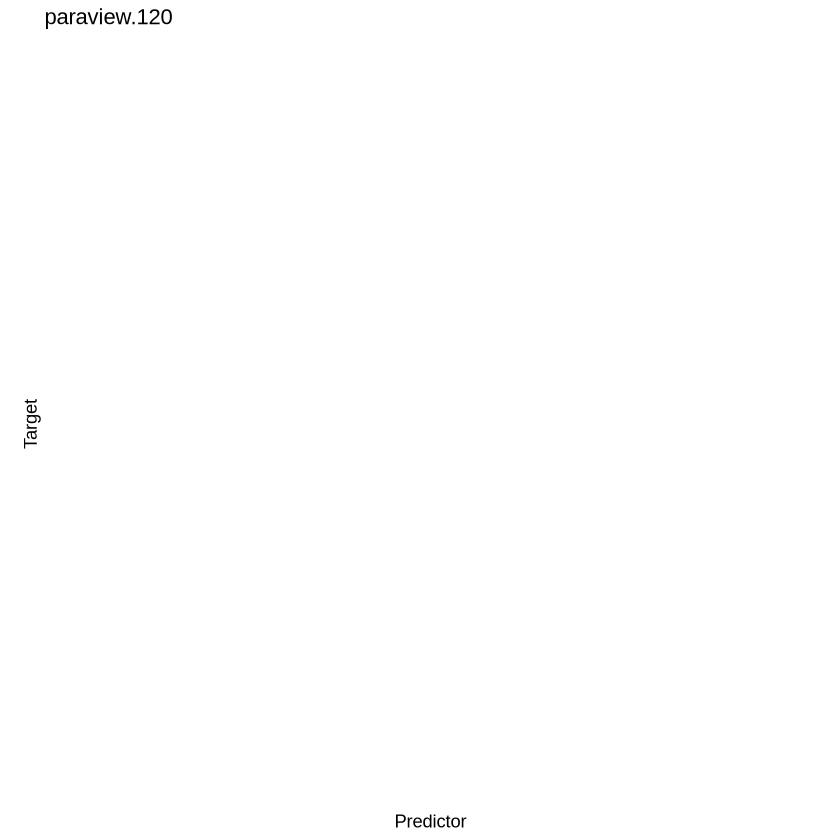

In [43]:
layout_scale <- 0.475  # Fig 4j is placed at 47.5% of its saved size
plot_improvement_stats(cluster_common, measure = "gain.R2", trim = c_trim)
ggsave(filename = "../../figures/fig4/kasumi_cluster_common_gain.pdf",
       plot = last_plot() + paper_theme(layout_scale), width = 2, height = 3)
plot_interaction_heatmap(cluster_common, "juxtaview.40", clean = TRUE, correlation = TRUE, trim = c_trim, 
    cutoff = c_cutoff)
plot_interaction_communities(cluster_common, view = "juxtaview.40", 
    trim = c_trim, cutoff = c_cutoff,
    path = "../../data/kasumi_cluster_common_juxtaview.graphml")
plot_interaction_heatmap(cluster_common, "paraview.120", clean = TRUE, correlation = TRUE, trim = c_trim, 
    cutoff = c_cutoff)